In [ ]:
from pathlib import Path

In [ ]:
INPUT_DIR = Path(
    '/content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_raw'
)

OUTPUT_DIR = Path(
    '/content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed'
)

WORK_DIR = Path('/content/genshin_work')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

matches = list(Path('/content/drive/MyDrive').rglob('genshin_raw'))

print("검색된 폴더:")
for folder in matches:
    print(folder)

검색된 폴더:
/content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_raw


In [ ]:
INPUT_DIR = matches[0]
OUTPUT_DIR = INPUT_DIR.parent / 'genshin_processed'
WORK_DIR = Path('/content/genshin_work')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

print("입력 폴더:", INPUT_DIR)
print("출력 폴더:", OUTPUT_DIR)
print("입력 폴더 존재:", INPUT_DIR.exists())
print("출력 폴더 존재:", OUTPUT_DIR.exists())

print("\n입력 파일 목록:")
for file in sorted(INPUT_DIR.iterdir()):
    print("-", file.name)

입력 폴더: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_raw
출력 폴더: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed
입력 폴더 존재: True
출력 폴더 존재: True

입력 파일 목록:
- 20220831原神抽卡数据集.zip.001
- 20220831原神抽卡数据集.zip.002
- 20220831原神抽卡数据集.zip.003
- 20220831原神抽卡数据集.zip.zip
- genshin_cost_estimate.py
- player_index.csv
- readme.md


In [ ]:
import shutil

part_names = [
    '20220831原神抽卡数据集.zip.001',
    '20220831原神抽卡数据集.zip.002',
    '20220831原神抽卡数据集.zip.003'
]

part_files = [INPUT_DIR / name for name in part_names]
combined_zip = WORK_DIR / 'genshin_dataset_combined.zip'

# 분할파일 존재 여부 확인
for part in part_files:
    if not part.exists():
        raise FileNotFoundError(f'파일을 찾을 수 없습니다: {part}')

# .001 → .002 → .003 순서로 결합
with combined_zip.open('wb') as output_file:
    for part in part_files:
        print(f'결합 중: {part.name} ({part.stat().st_size:,} bytes)')

        with part.open('rb') as input_file:
            shutil.copyfileobj(input_file, output_file)

print('\n결합 완료!')
print('결합 파일:', combined_zip)
print(f'결합 파일 크기: {combined_zip.stat().st_size:,} bytes')

# ZIP 파일 시작 문자 확인
with combined_zip.open('rb') as file:
    print('파일 헤더:', file.read(4))

결합 중: 20220831原神抽卡数据集.zip.001 (52,428,800 bytes)
결합 중: 20220831原神抽卡数据集.zip.002 (52,428,800 bytes)
결합 중: 20220831原神抽卡数据集.zip.003 (32,473,586 bytes)

결합 완료!
결합 파일: /content/genshin_work/genshin_dataset_combined.zip
결합 파일 크기: 137,331,186 bytes
파일 헤더: b'PK\x03\x04'


In [ ]:
import zipfile

EXTRACT_DIR = WORK_DIR / 'extracted'
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

password = b'OneBST'

with zipfile.ZipFile(combined_zip, 'r') as zip_file:
    members = zip_file.infolist()
    print(f'압축 내부 항목 수: {len(members):,}개')

    for index, member in enumerate(members, start=1):
        zip_file.extract(member, path=EXTRACT_DIR, pwd=password)

        if index % 1000 == 0:
            print(f'압축 해제 중: {index:,}/{len(members):,}')

print('\n압축 해제 완료!')
print('압축 해제 위치:', EXTRACT_DIR)

csv_files = sorted(EXTRACT_DIR.rglob('*.csv'))

print(f'발견된 사용자 CSV: {len(csv_files):,}개')
print('첫 번째 CSV:', csv_files[0] if csv_files else '없음')

압축 내부 항목 수: 16,290개
압축 해제 중: 1,000/16,290
압축 해제 중: 2,000/16,290
압축 해제 중: 3,000/16,290
압축 해제 중: 4,000/16,290
압축 해제 중: 5,000/16,290
압축 해제 중: 6,000/16,290
압축 해제 중: 7,000/16,290
압축 해제 중: 8,000/16,290
압축 해제 중: 9,000/16,290
압축 해제 중: 10,000/16,290
압축 해제 중: 11,000/16,290
압축 해제 중: 12,000/16,290
압축 해제 중: 13,000/16,290
압축 해제 중: 14,000/16,290
압축 해제 중: 15,000/16,290
압축 해제 중: 16,000/16,290

압축 해제 완료!
압축 해제 위치: /content/genshin_work/extracted
발견된 사용자 CSV: 16,289개
첫 번째 CSV: /content/genshin_work/extracted/player_data/0002384df0435138.csv


In [ ]:
import pandas as pd

sample_file = csv_files[0]

sample_df = pd.read_csv(
    sample_file,
    dtype={
        'name': 'string',
        'gacha_type': 'int16',
        'item_type': 'int8',
        'rank_type': 'int8',
        'gacha_id': 'string',
        'gacha_time': 'string'
    }
)

# 원본 중국어 이름 보존
sample_df = sample_df.rename(columns={'name': 'name_zh'})

# 파일명에서 익명 사용자 ID 추출
sample_df.insert(0, 'user_id', sample_file.stem)

# 시간 자료형 변환
sample_df['gacha_time'] = pd.to_datetime(
    sample_df['gacha_time'],
    errors='coerce'
)

# 코드값을 한국어로 표시
gacha_type_map = {
    100: '초보자 기원',
    200: '상시 기원',
    301: '캐릭터 이벤트 기원 1',
    302: '무기 이벤트 기원',
    400: '캐릭터 이벤트 기원 2'
}

item_type_map = {
    0: '캐릭터',
    1: '무기'
}

sample_df['gacha_type_ko'] = (
    sample_df['gacha_type'].map(gacha_type_map).fillna('알 수 없음')
)

sample_df['item_type_ko'] = (
    sample_df['item_type'].map(item_type_map).fillna('알 수 없음')
)

print('사용자 ID:', sample_file.stem)
print('뽑기 기록 수:', len(sample_df))
print('열 목록:', sample_df.columns.tolist())

display(sample_df.head(10))

print('\n가챠 종류별 개수')
display(sample_df['gacha_type_ko'].value_counts())

print('\n등급별 개수')
display(sample_df['rank_type'].value_counts().sort_index())

사용자 ID: 0002384df0435138
뽑기 기록 수: 130
열 목록: ['user_id', 'name_zh', 'gacha_type', 'item_type', 'rank_type', 'gacha_id', 'gacha_time', 'gacha_type_ko', 'item_type_ko']


,user_id,name_zh,gacha_type,item_type,rank_type,gacha_id,gacha_time,gacha_type_ko,item_type_ko
0,0002384df0435138,冷刃,200,1,3,1655993160001405338,2022-06-23 22:43:06,상시 기원,무기
1,0002384df0435138,冷刃,200,1,3,1655993160001405438,2022-06-23 22:43:06,상시 기원,무기
2,0002384df0435138,铁影阔剑,200,1,3,1655993160001405538,2022-06-23 22:43:06,상시 기원,무기
3,0002384df0435138,翡玉法球,200,1,3,1655993160001405638,2022-06-23 22:43:06,상시 기원,무기
4,0002384df0435138,神射手之誓,200,1,3,1655993160001405738,2022-06-23 22:43:06,상시 기원,무기
5,0002384df0435138,冷刃,200,1,3,1655993160001405838,2022-06-23 22:43:06,상시 기원,무기
6,0002384df0435138,铁影阔剑,200,1,3,1655993160001405938,2022-06-23 22:43:06,상시 기원,무기
7,0002384df0435138,迪卢克,200,0,5,1655993160001406038,2022-06-23 22:43:06,상시 기원,캐릭터
8,0002384df0435138,弹弓,200,1,3,1655993160001406138,2022-06-23 22:43:06,상시 기원,무기
9,0002384df0435138,笛剑,200,1,4,1655993160001406238,2022-06-23 22:43:06,상시 기원,무기



가챠 종류별 개수


,count
gacha_type_ko,
캐릭터 이벤트 기원 1,72
상시 기원,58



등급별 개수


,count
rank_type,
3,115
4,14
5,1


In [ ]:
import requests
import pandas as pd

TRANSLATION_FILE = OUTPUT_DIR / 'name_translation.csv'
UIGF_URL = 'https://api.uigf.org/dict/genshin/{lang}.json'

def download_dictionary(lang):
    url = UIGF_URL.format(lang=lang)
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.json()

# 중국어·한국어 공식 명칭 사전 다운로드
chs_dict = download_dictionary('chs')
kr_dict = download_dictionary('kr')

# 한국어 사전: 아이템 ID → 한국어 이름
id_to_ko = {}

for name_ko, item_id in kr_dict.items():
    id_to_ko.setdefault(str(item_id), name_ko)

# 중국어 이름 → 아이템 ID → 한국어 이름
translation_rows = []

for name_zh, item_id in chs_dict.items():
    name_ko = id_to_ko.get(str(item_id))

    if name_ko:
        translation_rows.append({
            'item_id': str(item_id),
            'name_zh': name_zh,
            'name_ko': name_ko
        })

translation_df = (
    pd.DataFrame(translation_rows)
    .drop_duplicates(subset='name_zh')
    .sort_values('item_id')
    .reset_index(drop=True)
)

# 구글 드라이브에 번역표 저장
translation_df.to_csv(
    TRANSLATION_FILE,
    index=False,
    encoding='utf-8-sig'
)

print('중국어 사전:', len(chs_dict))
print('한국어 사전:', len(kr_dict))
print('생성된 번역 대응표:', len(translation_df))
print('저장 위치:', TRANSLATION_FILE)

display(translation_df.head(10))

중국어 사전: 372
한국어 사전: 372
생성된 번역 대응표: 372
저장 위치: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/name_translation.csv


,item_id,name_zh,name_ko
0,10000002,神里绫华,카미사토 아야카
1,10000003,琴,진
2,10000006,丽莎,리사
3,10000014,芭芭拉,바바라
4,10000015,凯亚,케이아
5,10000016,迪卢克,다이루크
6,10000020,雷泽,레이저
7,10000021,安柏,엠버
8,10000022,温迪,벤티
9,10000023,香菱,향릉


In [ ]:
name_map = dict(
    zip(translation_df['name_zh'], translation_df['name_ko'])
)

sample_df['name_ko'] = sample_df['name_zh'].map(name_map)
sample_df['translation_ok'] = sample_df['name_ko'].notna()

# 번역이 없는 항목은 중국어 원문 유지
sample_df['name_ko'] = sample_df['name_ko'].fillna(
    sample_df['name_zh']
)

display(
    sample_df[
        [
            'name_zh',
            'name_ko',
            'translation_ok',
            'rank_type',
            'gacha_type_ko',
            'item_type_ko'
        ]
    ].head(20)
)

print(
    '번역 성공률:',
    f"{sample_df['translation_ok'].mean() * 100:.2f}%"
)

,name_zh,name_ko,translation_ok,rank_type,gacha_type_ko,item_type_ko
0,冷刃,차가운 칼날,True,3,상시 기원,무기
1,冷刃,차가운 칼날,True,3,상시 기원,무기
2,铁影阔剑,강철의 그림자,True,3,상시 기원,무기
3,翡玉法球,비취 오브,True,3,상시 기원,무기
4,神射手之誓,신궁의 서약,True,3,상시 기원,무기
5,冷刃,차가운 칼날,True,3,상시 기원,무기
6,铁影阔剑,강철의 그림자,True,3,상시 기원,무기
7,迪卢克,다이루크,True,5,상시 기원,캐릭터
8,弹弓,탄궁,True,3,상시 기원,무기
9,笛剑,피리검,True,4,상시 기원,무기


번역 성공률: 100.00%


In [ ]:
PARQUET_DIR = OUTPUT_DIR / 'pulls_parquet'
PARQUET_DIR.mkdir(parents=True, exist_ok=True)

print('전체 CSV 파일:', f'{len(csv_files):,}개')
print('Parquet 저장 위치:', PARQUET_DIR)

전체 CSV 파일: 16,289개
Parquet 저장 위치: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/pulls_parquet


In [ ]:
from collections import Counter
from tqdm.auto import tqdm
import pandas as pd
import gc

# 코드 변환표
GACHA_TYPE_KO = {
    '100': '초보자 기원',
    '200': '상시 기원',
    '301': '캐릭터 이벤트 기원 1',
    '302': '무기 이벤트 기원',
    '400': '캐릭터 이벤트 기원 2'
}

ITEM_TYPE_KO = {
    0: '캐릭터',
    1: '무기'
}

VALID_GACHA = set(GACHA_TYPE_KO.keys())
VALID_ITEM = set(ITEM_TYPE_KO.keys())
VALID_RANK = {3, 4, 5}

# 한 번에 처리할 사용자 파일 수
BATCH_FILES = 250

# 처리 결과 집계 변수
raw_rows = 0
clean_rows = 0
removed_rows = 0
translation_success_rows = 0

gacha_counts = Counter()
rank_counts = Counter()
item_counts = Counter()
unknown_names = Counter()
read_errors = []

min_time = None
max_time = None

total_batches = (len(csv_files) + BATCH_FILES - 1) // BATCH_FILES

print(f'전체 사용자 파일: {len(csv_files):,}개')
print(f'전체 처리 묶음: {total_batches:,}개')
print('전체 전처리를 시작합니다.\n')

for batch_no, start in enumerate(
    tqdm(
        range(0, len(csv_files), BATCH_FILES),
        desc='전체 CSV 처리'
    )
):
    frames = []

    # 사용자 CSV 250개씩 읽기
    for csv_path in csv_files[start:start + BATCH_FILES]:
        try:
            frame = pd.read_csv(
                csv_path,
                dtype={
                    'name': 'string',
                    'gacha_type': 'string',
                    'item_type': 'Int8',
                    'rank_type': 'Int8',
                    'gacha_id': 'string',
                    'gacha_time': 'string'
                }
            )

            frame.insert(0, 'user_id', csv_path.stem)
            frames.append(frame)

        except Exception as error:
            read_errors.append({
                'file': csv_path.name,
                'error': str(error)
            })

    if not frames:
        continue

    batch = pd.concat(frames, ignore_index=True)
    del frames

    raw_rows += len(batch)

    # 중국어 이름 열 보존
    batch = batch.rename(columns={'name': 'name_zh'})

    # 시간 자료형 변환
    batch['gacha_time'] = pd.to_datetime(
        batch['gacha_time'],
        errors='coerce'
    )

    # 정상적인 레코드만 선택
    valid_mask = (
        batch['user_id'].notna()
        & batch['name_zh'].notna()
        & batch['gacha_id'].notna()
        & batch['gacha_time'].notna()
        & batch['gacha_type'].isin(VALID_GACHA)
        & batch['item_type'].isin(VALID_ITEM)
        & batch['rank_type'].isin(VALID_RANK)
    )

    removed_rows += int((~valid_mask).sum())
    batch = batch.loc[valid_mask].copy()

    # 동일 사용자의 중복 뽑기 기록 제거
    before_dedup = len(batch)

    batch = batch.drop_duplicates(
        subset=['user_id', 'gacha_id'],
        keep='first'
    )

    removed_rows += before_dedup - len(batch)

    # 중국어 이름 → 한국어 이름
    batch['name_ko'] = batch['name_zh'].map(name_map)
    batch['translation_ok'] = batch['name_ko'].notna()

    translation_success_rows += int(
        batch['translation_ok'].sum()
    )

    missing_mask = ~batch['translation_ok']

    unknown_names.update(
        batch.loc[missing_mask, 'name_zh']
        .value_counts()
        .to_dict()
    )

    # 번역표에 없는 항목은 중국어 원문 보존
    batch.loc[missing_mask, 'name_ko'] = (
        batch.loc[missing_mask, 'name_zh']
    )

    # 숫자 코드에 한국어 설명 추가
    batch['gacha_type_ko'] = (
        batch['gacha_type'].map(GACHA_TYPE_KO)
    )

    batch['item_type_ko'] = (
        batch['item_type'].map(ITEM_TYPE_KO)
    )

    # 사용자별 시간순 정렬
    batch = batch.sort_values(
        ['user_id', 'gacha_time', 'gacha_id']
    )

    # 최종 열 순서
    batch = batch[
        [
            'user_id',
            'name_zh',
            'name_ko',
            'translation_ok',
            'gacha_type',
            'gacha_type_ko',
            'item_type',
            'item_type_ko',
            'rank_type',
            'gacha_id',
            'gacha_time'
        ]
    ]

    # 통계 집계
    clean_rows += len(batch)

    gacha_counts.update(
        batch['gacha_type'].value_counts().to_dict()
    )

    rank_counts.update(
        batch['rank_type'].value_counts().to_dict()
    )

    item_counts.update(
        batch['item_type'].value_counts().to_dict()
    )

    if len(batch) > 0:
        current_min = batch['gacha_time'].min()
        current_max = batch['gacha_time'].max()

        if min_time is None or current_min < min_time:
            min_time = current_min

        if max_time is None or current_max > max_time:
            max_time = current_max

    # 묶음별 Parquet 저장
    output_file = (
        PARQUET_DIR / f'part-{batch_no:04d}.parquet'
    )

    batch.to_parquet(
        output_file,
        index=False,
        compression='zstd'
    )

    del batch
    gc.collect()

print('\n전체 전처리 완료!')
print('원본 행:', f'{raw_rows:,}')
print('정제 후 행:', f'{clean_rows:,}')
print('제거된 행:', f'{removed_rows:,}')
print('읽기 실패 파일:', len(read_errors))
print('데이터 기간:', min_time, '~', max_time)

if clean_rows > 0:
    translation_rate = (
        translation_success_rows / clean_rows * 100
    )

    print(f'전체 번역 성공률: {translation_rate:.2f}%')

print('생성된 Parquet:', len(list(PARQUET_DIR.glob("part-*.parquet"))))

전체 사용자 파일: 16,289개
전체 처리 묶음: 66개
전체 전처리를 시작합니다.



전체 CSV 처리:   0%|          | 0/66 [00:00<?, ?it/s]


전체 전처리 완료!
원본 행: 15,599,315
정제 후 행: 15,598,804
제거된 행: 511
읽기 실패 파일: 0
데이터 기간: 2020-12-03 23:35:23 ~ 2022-07-26 20:57:25
전체 번역 성공률: 99.75%
생성된 Parquet: 66


In [ ]:
import json
import pandas as pd

# 번역되지 않은 이름 목록
unmapped_df = pd.DataFrame(
    [
        {
            'name_zh': name,
            'record_count': int(count)
        }
        for name, count in unknown_names.most_common()
    ]
)

UNMAPPED_FILE = OUTPUT_DIR / 'untranslated_names.csv'

unmapped_df.to_csv(
    UNMAPPED_FILE,
    index=False,
    encoding='utf-8-sig'
)

print('번역되지 않은 이름 종류:', len(unmapped_df))
print('번역되지 않은 전체 기록:', f'{unmapped_df["record_count"].sum():,}')
print('저장 위치:', UNMAPPED_FILE)

display(unmapped_df.head(30))

번역되지 않은 이름 종류: 159
번역되지 않은 전체 기록: 38,522
저장 위치: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/untranslated_names.csv


,name_zh,record_count
0,鐵影闊劍,3476
1,鴉羽弓,3469
2,魔導緒論,3419
3,彈弓,3412
4,沐浴龍血的劍,3394
5,飛天御劍,3373
6,討龍英傑譚,3371
7,黑纓槍,3357
8,黎明神劍,3303
9,九條裟羅,312


In [ ]:
summary = {
    'user_file_count': len(csv_files),
    'raw_rows': int(raw_rows),
    'clean_rows': int(clean_rows),
    'removed_rows': int(removed_rows),
    'read_error_files': len(read_errors),
    'translation_success_rate': round(
        translation_success_rows / clean_rows * 100,
        4
    ),
    'start_time': str(min_time),
    'end_time': str(max_time),
    'parquet_file_count': len(
        list(PARQUET_DIR.glob('part-*.parquet'))
    ),
    'gacha_type_counts': {
        str(key): int(value)
        for key, value in gacha_counts.items()
    },
    'rank_counts': {
        str(key): int(value)
        for key, value in rank_counts.items()
    },
    'item_type_counts': {
        str(key): int(value)
        for key, value in item_counts.items()
    }
}

SUMMARY_FILE = OUTPUT_DIR / 'processing_summary.json'

with open(SUMMARY_FILE, 'w', encoding='utf-8') as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2
    )

print('처리 요약 저장 완료:', SUMMARY_FILE)
display(pd.DataFrame([summary]))

처리 요약 저장 완료: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/processing_summary.json


,user_file_count,raw_rows,clean_rows,removed_rows,read_error_files,translation_success_rate,start_time,end_time,parquet_file_count,gacha_type_counts,rank_counts,item_type_counts
0,16289,15599315,15598804,511,0,99.753,2020-12-03 23:35:23,2022-07-26 20:57:25,66,"{'301': 8234223, '302': 2839412, '200': 233642...","{'3': 13259840, '4': 2081668, '5': 257296}","{'1': 14202933, '0': 1395871}"


In [ ]:
!pip -q install duckdb polars pyarrow

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import duckdb
import shutil

# 현재 사용 중인 경로
BASE_DIR = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2"
)

PROCESSED_DIR = BASE_DIR / "genshin_processed"
PARTS_DIR = PROCESSED_DIR / "pulls_parquet"

# 앞으로 분석에 사용할 최종 파일
FINAL_PARQUET = PROCESSED_DIR / "genshin_analysis.parquet"

# Colab 임시 저장 위치
TEMP_PARQUET = Path("/content/genshin_analysis.parquet")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if FINAL_PARQUET.exists():
    print("이미 최종 Parquet 파일이 있습니다.")
    print("파일 위치:", FINAL_PARQUET)

else:
    part_files = sorted(PARTS_DIR.glob("part-*.parquet"))

    if not part_files:
        raise FileNotFoundError(
            "part-XXXX.parquet 파일을 찾지 못했습니다.\n"
            "먼저 기존 전처리 코드를 한 번 실행해 주세요.\n"
            f"확인 경로: {PARTS_DIR}"
        )

    print(f"발견된 Parquet 조각: {len(part_files):,}개")

    total_part_size = sum(
        file.stat().st_size for file in part_files
    )

    free_space = shutil.disk_usage("/content").free

    print(
        f"조각 파일 전체 크기: "
        f"{total_part_size / 1024**3:.2f}GB"
    )
    print(
        f"Colab 남은 공간: "
        f"{free_space / 1024**3:.2f}GB"
    )

    # Colab 로컬 공간이 충분하면 로컬에서 만든 뒤
    # Google Drive로 복사한다.
    if free_space > total_part_size * 1.3:
        save_target = TEMP_PARQUET
        print("Colab 임시 공간에서 파일을 합칩니다.")
    else:
        save_target = FINAL_PARQUET
        print("로컬 공간이 부족하여 Drive에 직접 저장합니다.")

    # DuckDB에 전달할 파일 목록
    part_list_sql = ", ".join(
        "'" + str(file).replace("'", "''") + "'"
        for file in part_files
    )

    target_sql = str(save_target).replace("'", "''")

    con = duckdb.connect(database=":memory:")

    con.execute(
        f"""
        COPY (
            SELECT *
            FROM read_parquet(
                [{part_list_sql}],
                union_by_name = true
            )
        )
        TO '{target_sql}'
        (
            FORMAT PARQUET,
            COMPRESSION ZSTD,
            ROW_GROUP_SIZE 250000
        )
        """
    )

    con.close()

    # 로컬에서 만들었다면 Drive로 복사
    if save_target == TEMP_PARQUET:
        print("Google Drive로 복사하고 있습니다...")
        shutil.copy2(TEMP_PARQUET, FINAL_PARQUET)

    # 최종 검증
    con = duckdb.connect(database=":memory:")

    total_rows = con.execute(
        """
        SELECT COUNT(*)
        FROM read_parquet(?)
        """,
        [str(FINAL_PARQUET)]
    ).fetchone()[0]

    columns = con.execute(
        """
        DESCRIBE
        SELECT *
        FROM read_parquet(?)
        """,
        [str(FINAL_PARQUET)]
    ).fetchall()

    con.close()

    print("\n최종 Parquet 생성 완료!")
    print("파일 위치:", FINAL_PARQUET)
    print(f"전체 기록 수: {total_rows:,}행")
    print(f"컬럼 수: {len(columns):,}개")

Mounted at /content/drive
발견된 Parquet 조각: 66개
조각 파일 전체 크기: 0.13GB
Colab 남은 공간: 87.23GB
Colab 임시 공간에서 파일을 합칩니다.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Google Drive로 복사하고 있습니다...

최종 Parquet 생성 완료!
파일 위치: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/genshin_analysis.parquet
전체 기록 수: 15,598,804행
컬럼 수: 11개


In [ ]:
!pip -q install polars pyarrow

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import polars as pl

FINAL_PARQUET = Path(
    "/content/drive/MyDrive/캡스톤 2/"
    "capstonedata2/genshin_processed/"
    "genshin_analysis.parquet"
)

if not FINAL_PARQUET.exists():
    raise FileNotFoundError(
        "genshin_analysis.parquet 파일이 없습니다.\n"
        "먼저 최초 전처리 및 최종 파일 생성 코드를 실행해 주세요."
    )

# 전체 데이터를 메모리에 올리지 않고 지연 로딩
pulls = pl.scan_parquet(FINAL_PARQUET)

print("분석용 Parquet 연결 완료")
print("파일 위치:", FINAL_PARQUET)

# 컬럼 확인
print("\n데이터 구조")
print(pulls.collect_schema())

# 처음 10행만 확인
display(pulls.head(10).collect())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
분석용 Parquet 연결 완료
파일 위치: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/genshin_analysis.parquet

데이터 구조
Schema({'user_id': String, 'name_zh': String, 'name_ko': String, 'translation_ok': Boolean, 'gacha_type': String, 'gacha_type_ko': String, 'item_type': Int8, 'item_type_ko': String, 'rank_type': Int8, 'gacha_id': String, 'gacha_time': Datetime(time_unit='ns', time_zone=None)})


user_id,name_zh,name_ko,translation_ok,gacha_type,gacha_type_ko,item_type,item_type_ko,rank_type,gacha_id,gacha_time
str,str,str,bool,str,str,i8,str,i8,str,datetime[ns]
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405338""",2022-06-23 22:43:06
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405438""",2022-06-23 22:43:06
"""0002384df0435138""","""铁影阔剑""","""강철의 그림자""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405538""",2022-06-23 22:43:06
"""0002384df0435138""","""翡玉法球""","""비취 오브""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405638""",2022-06-23 22:43:06
"""0002384df0435138""","""神射手之誓""","""신궁의 서약""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405738""",2022-06-23 22:43:06
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405838""",2022-06-23 22:43:06
"""0002384df0435138""","""铁影阔剑""","""강철의 그림자""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405938""",2022-06-23 22:43:06
"""0002384df0435138""","""迪卢克""","""다이루크""",true,"""200""","""상시 기원""",0,"""캐릭터""",5,"""1655993160001406038""",2022-06-23 22:43:06
"""0002384df0435138""","""弹弓""","""탄궁""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001406138""",2022-06-23 22:43:06


In [ ]:
five_star_summary = (
    pulls
    .select([
        pl.len().alias("전체_뽑기_수"),

        (
            pl.col("rank_type")
            .cast(pl.Utf8) == "5"
        )
        .sum()
        .alias("5성_획득_수")
    ])
    .with_columns(
        (
            pl.col("5성_획득_수")
            / pl.col("전체_뽑기_수")
            * 100
        )
        .alias("5성_획득률")
    )
    .collect()
)

display(five_star_summary)

전체_뽑기_수,5성_획득_수,5성_획득률
u32,u32,f64
15598804,257296,1.64946


In [ ]:
user_pull_count = (
    pulls
    .group_by("user_id")
    .agg(
        pl.len().alias("뽑기_횟수")
    )
    .sort(
        "뽑기_횟수",
        descending=True
    )
    .collect()
)

display(user_pull_count.head(20))

user_id,뽑기_횟수
str,u32
"""b7246212575e4213""",36642
"""a670e1b461f67562""",18319
"""51c8d734077b6296""",15579
"""a7dbbc7607046561""",15043
"""28ee36d164153153""",14057
…,…
"""5534929437506907""",10345
"""2b6dce439f118289""",10292
"""ffcb56009c2e4509""",10237


In [ ]:
import polars as pl

PARQUET_PATH = (
    "/content/drive/MyDrive/캡스톤 2/"
    "capstonedata2/genshin_processed/genshin_analysis.parquet"
)

# Parquet 파일을 지연 방식으로 불러오기
lf = pl.scan_parquet(PARQUET_PATH)

print("데이터 연결 완료")
print(lf.collect_schema())

데이터 연결 완료
Schema({'user_id': String, 'name_zh': String, 'name_ko': String, 'translation_ok': Boolean, 'gacha_type': String, 'gacha_type_ko': String, 'item_type': Int8, 'item_type_ko': String, 'rank_type': Int8, 'gacha_id': String, 'gacha_time': Datetime(time_unit='ns', time_zone=None)})


In [ ]:
# 데이터 품질 점검
quality_check = (
    lf.select(
        pl.len().alias("전체_기록수"),
        pl.col("user_id").n_unique().alias("사용자수"),
        pl.col("user_id").is_null().sum().alias("유저ID_결측"),
        pl.col("gacha_time").is_null().sum().alias("시간_결측"),
        pl.col("rank_type").is_null().sum().alias("등급_결측"),
        pl.col("name_zh").is_null().sum().alias("아이템명_결측"),
        pl.col("name_ko").is_null().sum().alias("번역명_결측")
    )
    .collect()
)

display(quality_check)

전체_기록수,사용자수,유저ID_결측,시간_결측,등급_결측,아이템명_결측,번역명_결측
u32,u32,u32,u32,u32,u32,u32
15598804,16289,0,0,0,0,0


In [ ]:
# 자료형 정리 및 기본 파생변수 생성
analysis_lf = (
    lf.with_columns(
        pl.col("gacha_time")
        .cast(pl.Utf8)
        .str.strptime(
            pl.Datetime,
            format="%Y-%m-%d %H:%M:%S",
            strict=False
        ),

        pl.col("rank_type")
        .cast(pl.Int8, strict=False),

        pl.col("user_id")
        .cast(pl.Utf8)
        .str.strip_chars()
    )
    .filter(
        pl.col("user_id").is_not_null()
        & pl.col("gacha_time").is_not_null()
        & pl.col("rank_type").is_in([3, 4, 5])
    )
    .with_columns(
        (pl.col("rank_type") == 5).alias("is_five_star"),
        (pl.col("rank_type") == 4).alias("is_four_star"),
        pl.col("gacha_time").dt.date().alias("gacha_date"),
        pl.col("gacha_time").dt.strftime("%Y-%m").alias("gacha_month")
    )
)

# 결과 확인
display(analysis_lf.head(10).collect())

user_id,name_zh,name_ko,translation_ok,gacha_type,gacha_type_ko,item_type,item_type_ko,rank_type,gacha_id,gacha_time,is_five_star,is_four_star,gacha_date,gacha_month
str,str,str,bool,str,str,i8,str,i8,str,datetime[μs],bool,bool,date,str


In [ ]:
# 전처리 완료 데이터를 별도 Parquet 파일로 저장
CLEAN_PATH = (
    "/content/drive/MyDrive/캡스톤 2/"
    "capstonedata2/genshin_processed/genshin_analysis_clean.parquet"
)

analysis_lf.sink_parquet(
    CLEAN_PATH,
    compression="zstd"
)

print("전처리 데이터 저장 완료")
print(CLEAN_PATH)

전처리 데이터 저장 완료
/content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/genshin_analysis_clean.parquet


In [ ]:
# 저장된 전처리 데이터 확인
clean_lf = pl.scan_parquet(CLEAN_PATH)

clean_summary = clean_lf.select(
    pl.len().alias("전체_기록수"),
    pl.col("user_id").n_unique().alias("사용자수"),
    pl.col("is_five_star").sum().alias("5성_획득수"),
    pl.col("is_four_star").sum().alias("4성_획득수"),
    pl.col("gacha_time").min().alias("최초_기록일시"),
    pl.col("gacha_time").max().alias("최종_기록일시")
).collect()

display(clean_summary)

전체_기록수,사용자수,5성_획득수,4성_획득수,최초_기록일시,최종_기록일시
u32,u32,u32,u32,datetime[μs],datetime[μs]
0,0,0,0,null,null


In [ ]:
# 원본 컬럼 자료형 확인
schema = lf.collect_schema()
print(schema)

# gacha_time의 기존 자료형에 맞춰 변환
if schema["gacha_time"] == pl.String:
    time_expr = (
        pl.col("gacha_time")
        .str.to_datetime(strict=False)
        .alias("gacha_time")
    )
else:
    time_expr = (
        pl.col("gacha_time")
        .cast(pl.Datetime, strict=False)
        .alias("gacha_time")
    )

# 자료형 정리 및 파생변수 생성
analysis_lf = (
    lf.with_columns(
        time_expr,
        pl.col("rank_type").cast(pl.Int8, strict=False),
        pl.col("user_id").cast(pl.Utf8).str.strip_chars()
    )
    .with_columns(
        (pl.col("rank_type") == 5).alias("is_five_star"),
        (pl.col("rank_type") == 4).alias("is_four_star"),
        pl.col("gacha_time").dt.date().alias("gacha_date"),
        pl.col("gacha_time").dt.strftime("%Y-%m").alias("gacha_month")
    )
    .filter(
        pl.col("user_id").is_not_null()
        & pl.col("gacha_time").is_not_null()
        & pl.col("rank_type").is_in([3, 4, 5])
    )
)

# 저장 전에 반드시 행 개수 확인
check_fixed = analysis_lf.select(
    pl.len().alias("전처리후_기록수"),
    pl.col("gacha_time").is_null().sum().alias("시간_결측"),
    pl.col("rank_type").is_null().sum().alias("등급_결측")
).collect()

display(check_fixed)
display(analysis_lf.head(10).collect())

Schema({'user_id': String, 'name_zh': String, 'name_ko': String, 'translation_ok': Boolean, 'gacha_type': String, 'gacha_type_ko': String, 'item_type': Int8, 'item_type_ko': String, 'rank_type': Int8, 'gacha_id': String, 'gacha_time': Datetime(time_unit='ns', time_zone=None)})


전처리후_기록수,시간_결측,등급_결측
u32,u32,u32
15598804,0,0


user_id,name_zh,name_ko,translation_ok,gacha_type,gacha_type_ko,item_type,item_type_ko,rank_type,gacha_id,gacha_time,is_five_star,is_four_star,gacha_date,gacha_month
str,str,str,bool,str,str,i8,str,i8,str,datetime[μs],bool,bool,date,str
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405338""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405438""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""铁影阔剑""","""강철의 그림자""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405538""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""翡玉法球""","""비취 오브""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405638""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""神射手之誓""","""신궁의 서약""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405738""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""冷刃""","""차가운 칼날""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405838""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""铁影阔剑""","""강철의 그림자""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001405938""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""迪卢克""","""다이루크""",true,"""200""","""상시 기원""",0,"""캐릭터""",5,"""1655993160001406038""",2022-06-23 22:43:06,true,false,2022-06-23,"""2022-06"""
"""0002384df0435138""","""弹弓""","""탄궁""",true,"""200""","""상시 기원""",1,"""무기""",3,"""1655993160001406138""",2022-06-23 22:43:06,false,false,2022-06-23,"""2022-06"""


In [ ]:
# 정상 전처리 데이터를 최종 분석용 파일로 저장
READY_PATH = (
    "/content/drive/MyDrive/캡스톤 2/"
    "capstonedata2/genshin_processed/genshin_analysis_ready.parquet"
)

analysis_lf.sink_parquet(
    READY_PATH,
    compression="zstd"
)

print("최종 분석용 데이터 저장 완료")
print(READY_PATH)

최종 분석용 데이터 저장 완료
/content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/genshin_analysis_ready.parquet


In [ ]:
# 최종 분석용 파일 확인
ready_lf = pl.scan_parquet(READY_PATH)

ready_summary = ready_lf.select(
    pl.len().alias("전체_기록수"),
    pl.col("user_id").n_unique().alias("사용자수"),
    pl.col("is_five_star").sum().alias("5성_획득수"),
    pl.col("is_four_star").sum().alias("4성_획득수"),
    pl.col("gacha_time").min().alias("최초_기록일시"),
    pl.col("gacha_time").max().alias("최종_기록일시")
).collect()

display(ready_summary)

전체_기록수,사용자수,5성_획득수,4성_획득수,최초_기록일시,최종_기록일시
u32,u32,u32,u32,datetime[μs],datetime[μs]
15598804,16289,257296,2081668,2020-12-03 23:35:23,2022-07-26 20:57:25


In [ ]:
import polars as pl

READY_PATH = (
    "/content/drive/MyDrive/캡스톤 2/"
    "capstonedata2/genshin_processed/genshin_analysis_ready.parquet"
)

ready_lf = pl.scan_parquet(READY_PATH)

In [ ]:
# 그래프 한글 폰트 설치
!apt-get -qq install fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)

plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

print("한글 폰트 설정 완료")

Selecting previously unselected package fonts-nanum.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
한글 폰트 설정 완료


In [ ]:
# 등급별 획득 건수와 비율 집계
rank_summary = (
    ready_lf
    .group_by("rank_type")
    .agg(
        pl.len().alias("획득수")
    )
    .sort("rank_type")
    .with_columns(
        (
            pl.col("획득수")
            / pl.col("획득수").sum()
            * 100
        ).alias("획득비율")
    )
    .collect()
)

display(rank_summary)

rank_type,획득수,획득비율
i8,u32,f64
3,13259840,85.005491
4,2081668,13.345049
5,257296,1.64946


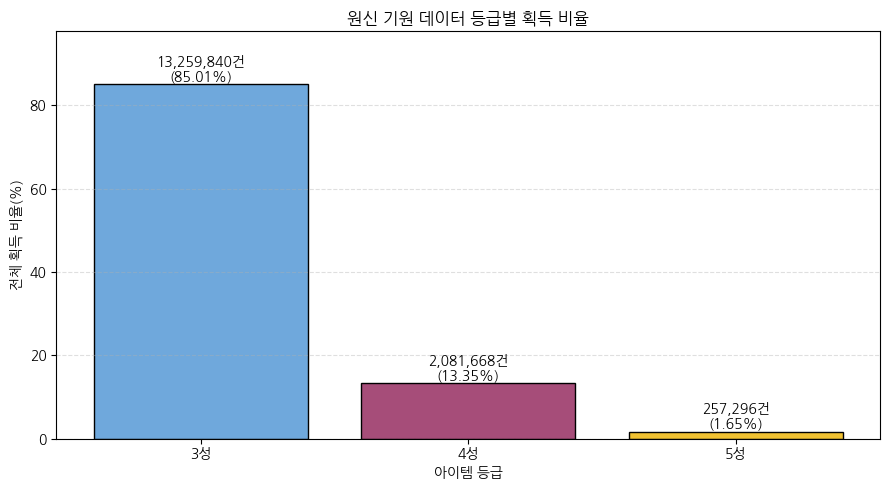

In [ ]:
# Polars 결과를 그래프용 Pandas 데이터로 변환
rank_pd = rank_summary.to_pandas()

labels = rank_pd["rank_type"].astype(str) + "성"
values = rank_pd["획득비율"]

colors = ["#6FA8DC", "#A64D79", "#F1C232"]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    values,
    color=colors,
    edgecolor="black"
)

for bar, count, rate in zip(
    bars,
    rank_pd["획득수"],
    rank_pd["획득비율"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{count:,}건\n({rate:.2f}%)",
        ha="center",
        fontsize=10
    )

plt.title("원신 기원 데이터 등급별 획득 비율")
plt.xlabel("아이템 등급")
plt.ylabel("전체 획득 비율(%)")
plt.ylim(0, max(values) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# 가챠 유형별 전체 뽑기 수와 5성 획득률 집계
gacha_summary = (
    ready_lf
    .group_by("gacha_type_ko")
    .agg(
        pl.len().alias("전체_뽑기수"),
        pl.col("is_five_star").sum().alias("5성_획득수"),
        pl.col("is_four_star").sum().alias("4성_획득수"),
        pl.col("user_id").n_unique().alias("참여_사용자수")
    )
    .with_columns(
        (
            pl.col("5성_획득수")
            / pl.col("전체_뽑기수")
            * 100
        ).alias("5성_획득률")
    )
    .sort("5성_획득률", descending=True)
    .collect()
)

display(gacha_summary)

gacha_type_ko,전체_뽑기수,5성_획득수,4성_획득수,참여_사용자수,5성_획득률
str,u32,u32,u32,u32,f64
"""무기 이벤트 기원""",2839412,52821,419221,14258,1.86028
"""캐릭터 이벤트 기원 1""",8234223,135188,1073634,16255,1.641782
"""캐릭터 이벤트 기원 2""",2076626,32867,270861,14992,1.582712
"""상시 기원""",2336423,35639,303029,16245,1.525366
"""초보자 기원""",112120,781,14923,6035,0.696575


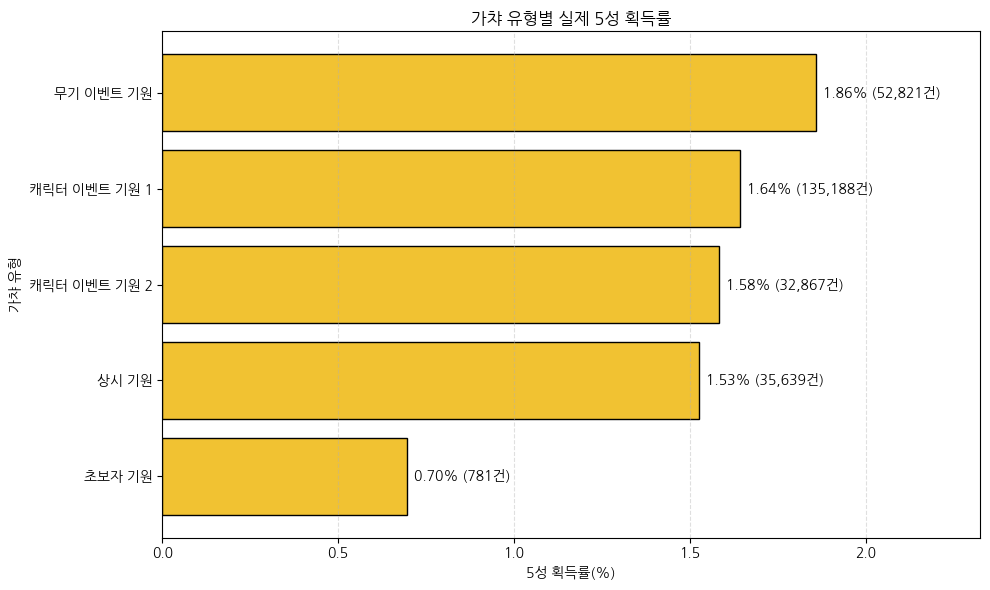

In [ ]:
# 가챠 유형별 5성 획득률 시각화
gacha_pd = (
    gacha_summary
    .sort("5성_획득률")
    .to_pandas()
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    gacha_pd["gacha_type_ko"],
    gacha_pd["5성_획득률"],
    color="#F1C232",
    edgecolor="black"
)

for bar, rate, count in zip(
    bars,
    gacha_pd["5성_획득률"],
    gacha_pd["5성_획득수"]
):
    plt.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}% ({count:,}건)",
        va="center",
        fontsize=10
    )

plt.title("가챠 유형별 실제 5성 획득률")
plt.xlabel("5성 획득률(%)")
plt.ylabel("가챠 유형")
plt.xlim(0, gacha_pd["5성_획득률"].max() * 1.25)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# 캐릭터 이벤트 기원 1·2를 하나의 유형으로 통합
grouped_gacha_lf = (
    ready_lf.with_columns(
        pl.when(
            pl.col("gacha_type_ko")
            .str.contains("캐릭터 이벤트 기원")
        )
        .then(pl.lit("캐릭터 이벤트 기원"))
        .otherwise(pl.col("gacha_type_ko"))
        .alias("analysis_gacha_type")
    )
)

grouped_summary = (
    grouped_gacha_lf
    .group_by("analysis_gacha_type")
    .agg(
        pl.len().alias("전체_뽑기수"),
        pl.col("is_five_star").sum().alias("5성_획득수"),
        pl.col("user_id").n_unique().alias("참여_사용자수")
    )
    .with_columns(
        (
            pl.col("5성_획득수")
            / pl.col("전체_뽑기수")
            * 100
        ).alias("실제_5성_획득률")
    )
    .sort("실제_5성_획득률", descending=True)
    .collect()
)

display(grouped_summary)

analysis_gacha_type,전체_뽑기수,5성_획득수,참여_사용자수,실제_5성_획득률
str,u32,u32,u32,f64
"""무기 이벤트 기원""",2839412,52821,14258,1.86028
"""캐릭터 이벤트 기원""",10310849,168055,16277,1.629885
"""상시 기원""",2336423,35639,16245,1.525366
"""초보자 기원""",112120,781,6035,0.696575


In [ ]:
# 비교에 사용할 공식 5성 확률
# 캐릭터·상시·무기 기원은 천장을 포함한 종합 확률 기준
official_rates = pl.DataFrame({
    "analysis_gacha_type": [
        "캐릭터 이벤트 기원",
        "무기 이벤트 기원",
        "상시 기원",
        "초보자 기원"
    ],
    "공식_5성_확률": [
        1.60,
        1.85,
        1.60,
        0.60
    ]
})

# 실제 확률과 공식 확률 연결
probability_comparison = (
    grouped_summary
    .join(
        official_rates,
        on="analysis_gacha_type",
        how="left"
    )
    .with_columns(
        (
            pl.col("실제_5성_획득률")
            - pl.col("공식_5성_확률")
        ).alias("확률차이")
    )
    .sort("analysis_gacha_type")
)

display(probability_comparison)

analysis_gacha_type,전체_뽑기수,5성_획득수,참여_사용자수,실제_5성_획득률,공식_5성_확률,확률차이
str,u32,u32,u32,f64,f64,f64
"""무기 이벤트 기원""",2839412,52821,14258,1.86028,1.85,0.01028
"""상시 기원""",2336423,35639,16245,1.525366,1.6,-0.074634
"""초보자 기원""",112120,781,6035,0.696575,0.6,0.096575
"""캐릭터 이벤트 기원""",10310849,168055,16277,1.629885,1.6,0.029885


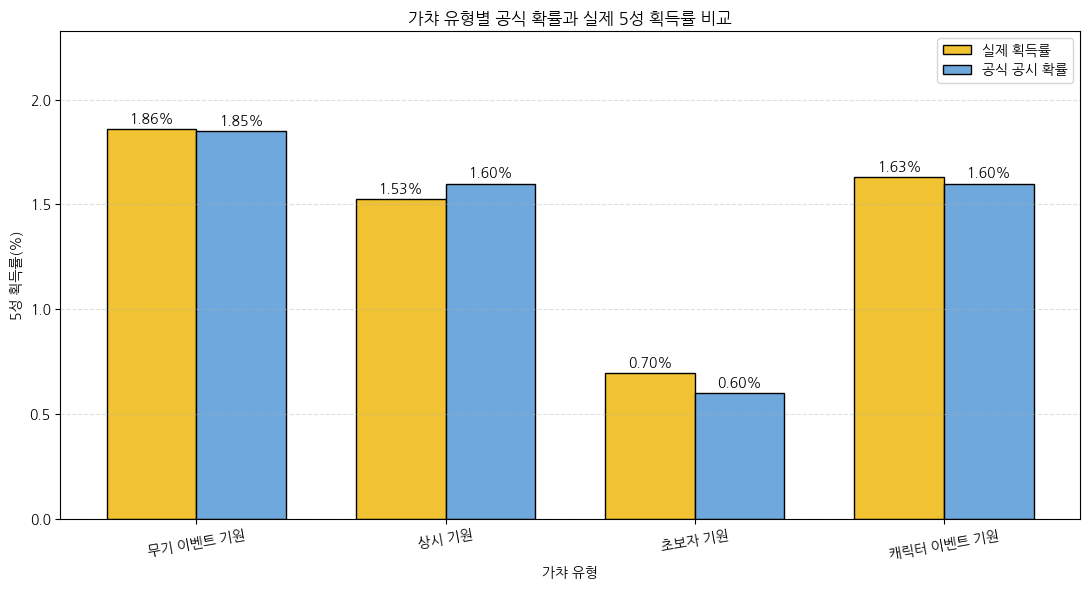

In [ ]:
import numpy as np

comparison_pd = probability_comparison.to_pandas()

labels = comparison_pd["analysis_gacha_type"]
actual = comparison_pd["실제_5성_획득률"]
official = comparison_pd["공식_5성_확률"]

x = np.arange(len(labels))
width = 0.36

plt.figure(figsize=(11, 6))

actual_bars = plt.bar(
    x - width / 2,
    actual,
    width,
    label="실제 획득률",
    color="#F1C232",
    edgecolor="black"
)

official_bars = plt.bar(
    x + width / 2,
    official,
    width,
    label="공식 공시 확률",
    color="#6FA8DC",
    edgecolor="black"
)

for bars in [actual_bars, official_bars]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.03,
            f"{bar.get_height():.2f}%",
            ha="center",
            fontsize=10
        )

plt.title("가챠 유형별 공식 확률과 실제 5성 획득률 비교")
plt.xlabel("가챠 유형")
plt.ylabel("5성 획득률(%)")
plt.xticks(x, labels, rotation=10)
plt.ylim(0, max(max(actual), max(official)) * 1.25)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 비교 결과를 Pandas로 변환
ci_pd = probability_comparison.to_pandas().copy()

# Wilson 방식 95% 신뢰구간
z = 1.96

n = ci_pd["전체_뽑기수"].astype(float)
x = ci_pd["5성_획득수"].astype(float)
p = x / n

denominator = 1 + (z**2 / n)

center = (
    p + (z**2 / (2 * n))
) / denominator

margin = (
    z
    * np.sqrt(
        (p * (1 - p) / n)
        + (z**2 / (4 * n**2))
    )
    / denominator
)

ci_pd["신뢰구간_하한"] = (center - margin) * 100
ci_pd["신뢰구간_상한"] = (center + margin) * 100

# 공식 확률이 신뢰구간에 포함되는지 확인
ci_pd["공식확률_신뢰구간포함"] = (
    (ci_pd["공식_5성_확률"] >= ci_pd["신뢰구간_하한"])
    & (ci_pd["공식_5성_확률"] <= ci_pd["신뢰구간_상한"])
)

display(
    ci_pd[
        [
            "analysis_gacha_type",
            "전체_뽑기수",
            "5성_획득수",
            "실제_5성_획득률",
            "공식_5성_확률",
            "신뢰구간_하한",
            "신뢰구간_상한",
            "공식확률_신뢰구간포함"
        ]
    ]
)

,analysis_gacha_type,전체_뽑기수,5성_획득수,실제_5성_획득률,공식_5성_확률,신뢰구간_하한,신뢰구간_상한,공식확률_신뢰구간포함
0,무기 이벤트 기원,2839412,52821,1.860280,1.85,1.844628,1.876061,True
1,상시 기원,2336423,35639,1.525366,1.60,1.509730,1.541161,False
2,초보자 기원,112120,781,0.696575,0.60,0.649553,0.746976,False
3,캐릭터 이벤트 기원,10310849,168055,1.629885,1.60,1.622174,1.637632,False


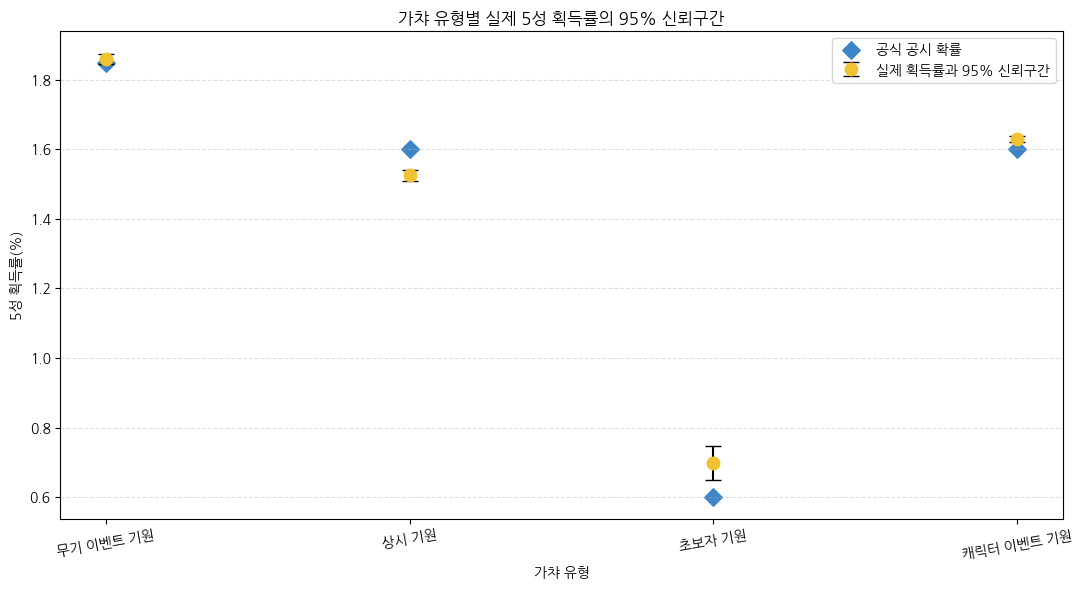

In [ ]:
labels = ci_pd["analysis_gacha_type"]
actual = ci_pd["실제_5성_획득률"]
official = ci_pd["공식_5성_확률"]

lower_error = actual - ci_pd["신뢰구간_하한"]
upper_error = ci_pd["신뢰구간_상한"] - actual

plt.figure(figsize=(11, 6))

plt.errorbar(
    labels,
    actual,
    yerr=[lower_error, upper_error],
    fmt="o",
    color="#F1C232",
    ecolor="black",
    capsize=6,
    markersize=9,
    label="실제 획득률과 95% 신뢰구간"
)

plt.scatter(
    labels,
    official,
    marker="D",
    color="#3D85C6",
    s=80,
    label="공식 공시 확률"
)

plt.title("가챠 유형별 실제 5성 획득률의 95% 신뢰구간")
plt.xlabel("가챠 유형")
plt.ylabel("5성 획득률(%)")
plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 1단계: Google Drive 연결 및 Parquet 파일 확인

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pyarrow.parquet as pq

PARQUET_PATH = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "genshin_processed/genshin_analysis_ready.parquet"
)

print("파일 존재 여부:", PARQUET_PATH.exists())

if PARQUET_PATH.exists():
    parquet_file = pq.ParquetFile(str(PARQUET_PATH))

    print("전체 데이터 수:", parquet_file.metadata.num_rows)
    print("행 그룹 수:", parquet_file.num_row_groups)
    print("컬럼 목록:")

    for column in parquet_file.schema.names:
        print("-", column)
else:
    print("Parquet 파일을 찾지 못했습니다.")
    print("입력된 경로:", PARQUET_PATH)

Mounted at /content/drive
파일 존재 여부: True
전체 데이터 수: 15598804
행 그룹 수: 60
컬럼 목록:
- user_id
- name_zh
- name_ko
- translation_ok
- gacha_type
- gacha_type_ko
- item_type
- item_type_ko
- rank_type
- gacha_id
- gacha_time
- is_five_star
- is_four_star
- gacha_date
- gacha_month


In [ ]:

# 2단계: 실제 데이터 10건 및 자료형 확인

import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(str(PARQUET_PATH))

# 첫 번째 행 그룹만 읽기
sample_table = parquet_file.read_row_group(0)

# 처음 10개 기록만 확인
sample_df = sample_table.slice(0, 10).to_pandas()

print("===== 실제 데이터 10건 =====")
display(sample_df)

print("\n===== 컬럼별 자료형 =====")
print(sample_df.dtypes)

print("\n===== 첫 번째 행 그룹 데이터 수 =====")
print(sample_table.num_rows)


===== 실제 데이터 10건 =====


,user_id,name_zh,name_ko,translation_ok,gacha_type,gacha_type_ko,item_type,item_type_ko,rank_type,gacha_id,gacha_time,is_five_star,is_four_star,gacha_date,gacha_month
0,0002384df0435138,冷刃,차가운 칼날,True,200,상시 기원,1,무기,3,1655993160001405338,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
1,0002384df0435138,冷刃,차가운 칼날,True,200,상시 기원,1,무기,3,1655993160001405438,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
2,0002384df0435138,铁影阔剑,강철의 그림자,True,200,상시 기원,1,무기,3,1655993160001405538,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
3,0002384df0435138,翡玉法球,비취 오브,True,200,상시 기원,1,무기,3,1655993160001405638,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
4,0002384df0435138,神射手之誓,신궁의 서약,True,200,상시 기원,1,무기,3,1655993160001405738,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
5,0002384df0435138,冷刃,차가운 칼날,True,200,상시 기원,1,무기,3,1655993160001405838,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
6,0002384df0435138,铁影阔剑,강철의 그림자,True,200,상시 기원,1,무기,3,1655993160001405938,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
7,0002384df0435138,迪卢克,다이루크,True,200,상시 기원,0,캐릭터,5,1655993160001406038,2022-06-23 22:43:06,True,False,2022-06-23,2022-06
8,0002384df0435138,弹弓,탄궁,True,200,상시 기원,1,무기,3,1655993160001406138,2022-06-23 22:43:06,False,False,2022-06-23,2022-06
9,0002384df0435138,笛剑,피리검,True,200,상시 기원,1,무기,4,1655993160001406238,2022-06-23 22:43:06,False,True,2022-06-23,2022-06



===== 컬럼별 자료형 =====
user_id                   object
name_zh                   object
name_ko                   object
translation_ok              bool
gacha_type                object
gacha_type_ko             object
item_type                   int8
item_type_ko              object
rank_type                   int8
gacha_id                  object
gacha_time        datetime64[us]
is_five_star                bool
is_four_star                bool
gacha_date                object
gacha_month               object
dtype: object

===== 첫 번째 행 그룹 데이터 수 =====
262144


In [ ]:

# 3단계: gacha_id 및 중복 기록 확인

import pandas as pd

# 이전 단계에서 읽은 첫 번째 행 그룹 사용
df_check = sample_table.to_pandas()

print("===== 검사 대상 =====")
print("검사 기록 수:", len(df_check))
print("사용자 수:", df_check["user_id"].nunique())

print("\n===== 중복 검사 =====")
print("gacha_id 중복:", df_check["gacha_id"].duplicated().sum())

print(
    "사용자 + gacha_id 중복:",
    df_check.duplicated(
        subset=["user_id", "gacha_id"]
    ).sum()
)

print("\n===== gacha_id 형식 확인 =====")
print("자료형:", df_check["gacha_id"].dtype)
print("숫자 변환 가능 비율:",
      pd.to_numeric(
          df_check["gacha_id"],
          errors="coerce"
      ).notna().mean() * 100, "%")

print("\n===== 기록 예시 =====")
display(
    df_check[
        ["user_id", "gacha_time", "gacha_id", "rank_type"]
    ].head(10)
)


===== 검사 대상 =====
검사 기록 수: 262144
사용자 수: 279

===== 중복 검사 =====
gacha_id 중복: 1
사용자 + gacha_id 중복: 0

===== gacha_id 형식 확인 =====
자료형: object
숫자 변환 가능 비율: 100.0 %

===== 기록 예시 =====


,user_id,gacha_time,gacha_id,rank_type
0,0002384df0435138,2022-06-23 22:43:06,1655993160001405338,3
1,0002384df0435138,2022-06-23 22:43:06,1655993160001405438,3
2,0002384df0435138,2022-06-23 22:43:06,1655993160001405538,3
3,0002384df0435138,2022-06-23 22:43:06,1655993160001405638,3
4,0002384df0435138,2022-06-23 22:43:06,1655993160001405738,3
5,0002384df0435138,2022-06-23 22:43:06,1655993160001405838,3
6,0002384df0435138,2022-06-23 22:43:06,1655993160001405938,3
7,0002384df0435138,2022-06-23 22:43:06,1655993160001406038,5
8,0002384df0435138,2022-06-23 22:43:06,1655993160001406138,3
9,0002384df0435138,2022-06-23 22:43:06,1655993160001406238,4


In [ ]:

# 4단계: 행 그룹별 사용자 분포 확인

import pandas as pd
import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(str(PARQUET_PATH))

group_stats = []
all_users = set()

for i in range(parquet_file.num_row_groups):

    # user_id 컬럼만 읽기
    table = parquet_file.read_row_group(
        i, columns=["user_id"]
    )

    users = table.column("user_id").to_pylist()
    unique_users = set(users)

    all_users.update(unique_users)

    group_stats.append({
        "row_group": i,
        "rows": len(users),
        "unique_users": len(unique_users)
    })

group_df = pd.DataFrame(group_stats)

print("===== 전체 사용자 분포 =====")
print("전체 행 그룹:", len(group_df))
print("고유 사용자 수:", len(all_users))

print("\n===== 행 그룹별 사용자 수 =====")
display(group_df.head(10))

print("\n===== 행 그룹 통계 =====")
print(group_df["unique_users"].describe())


===== 전체 사용자 분포 =====
전체 행 그룹: 60
고유 사용자 수: 16289

===== 행 그룹별 사용자 수 =====


,row_group,rows,unique_users
0,0,262144,279
1,1,262144,273
2,2,262144,259
3,3,262144,285
4,4,262144,287
5,5,262144,306
6,6,262144,267
7,7,262144,268
8,8,262144,290
9,9,262144,266



===== 행 그룹 통계 =====
count     60.000000
mean     272.466667
std       26.130356
min      126.000000
25%      263.000000
50%      274.500000
75%      286.000000
max      307.000000
Name: unique_users, dtype: float64


In [ ]:

# 5단계: 사용자 단위 데이터 분리

from sklearn.model_selection import train_test_split

# 앞 단계에서 확보한 전체 사용자 목록
user_list = sorted(all_users)

# 1차: 학습 70%, 나머지 30%
train_users, temp_users = train_test_split(
    user_list,
    test_size=0.30,
    random_state=42
)

# 2차: 검증 15%, 테스트 15%
val_users, test_users = train_test_split(
    temp_users,
    test_size=0.50,
    random_state=42
)

# 집합으로 변환
train_users = set(train_users)
val_users = set(val_users)
test_users = set(test_users)

print("===== 사용자 분리 결과 =====")
print("학습 사용자:", len(train_users))
print("검증 사용자:", len(val_users))
print("테스트 사용자:", len(test_users))

print("\n===== 중복 사용자 검사 =====")
print("학습-검증:", len(train_users & val_users))
print("학습-테스트:", len(train_users & test_users))
print("검증-테스트:", len(val_users & test_users))

print("\n전체 사용자:", len(
    train_users | val_users | test_users
))


===== 사용자 분리 결과 =====
학습 사용자: 11402
검증 사용자: 2443
테스트 사용자: 2444

===== 중복 사용자 검사 =====
학습-검증: 0
학습-테스트: 0
검증-테스트: 0

전체 사용자: 16289


In [ ]:

# 6단계: 사용자 그룹별 실제 기원 기록 수 확인

import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(str(PARQUET_PATH))

split_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

user_record_counts = {}

for i in range(parquet_file.num_row_groups):

    # user_id 컬럼만 불러오기
    table = parquet_file.read_row_group(
        i, columns=["user_id"]
    )

    # 사용자별 기록 개수 계산
    counts = table.column("user_id").to_pandas().value_counts()

    for user_id, count in counts.items():
        user_record_counts[user_id] = (
            user_record_counts.get(user_id, 0) + int(count)
        )

# 분할별 기록 수 계산
for user_id, count in user_record_counts.items():

    if user_id in train_users:
        split_counts["train"] += count

    elif user_id in val_users:
        split_counts["val"] += count

    elif user_id in test_users:
        split_counts["test"] += count

print("===== 데이터 분할별 기록 수 =====")
print("학습 데이터:", split_counts["train"])
print("검증 데이터:", split_counts["val"])
print("테스트 데이터:", split_counts["test"])

print("\n전체 기록:",
      sum(split_counts.values()))

print("\n===== 사용자별 기록 통계 =====")
import pandas as pd

user_counts = pd.Series(user_record_counts)

print(user_counts.describe())


===== 데이터 분할별 기록 수 =====
학습 데이터: 10750074
검증 데이터: 2411948
테스트 데이터: 2436782

전체 기록: 15598804

===== 사용자별 기록 통계 =====
count    16289.000000
mean       957.628093
std        958.793099
min          7.000000
25%        503.000000
50%        744.000000
75%       1109.000000
max      36642.000000
dtype: float64


In [ ]:

# 7단계: 학습용 정상 후보 사용자 선정

import numpy as np

TARGET_ROWS = 100000
rng = np.random.default_rng(42)

# 학습 그룹에 속한 사용자와 기록 수
train_user_counts = {
    uid: user_record_counts[uid]
    for uid in train_users
}

# 사용자 목록을 무작위로 섞기
shuffled_users = rng.permutation(
    list(train_user_counts.keys())
)

selected_train_users = set()
selected_rows = 0

for uid in shuffled_users:
    count = train_user_counts[uid]

    # 목표 기록 수를 넘지 않는 사용자만 선택
    if selected_rows + count <= TARGET_ROWS:
        selected_train_users.add(uid)
        selected_rows += count

    if selected_rows == TARGET_ROWS:
        break

print("===== 학습용 사용자 선정 결과 =====")
print("선정 사용자 수:", len(selected_train_users))
print("예상 기록 수:", selected_rows)
print("목표 기록 수:", TARGET_ROWS)
print("목표 대비 비율:",
      round(selected_rows / TARGET_ROWS * 100, 2), "%")

print("\n===== 안전성 검사 =====")
print("검증 사용자 중복:",
      len(selected_train_users & val_users))
print("테스트 사용자 중복:",
      len(selected_train_users & test_users))


===== 학습용 사용자 선정 결과 =====
선정 사용자 수: 116
예상 기록 수: 99998
목표 기록 수: 100000
목표 대비 비율: 100.0 %

===== 안전성 검사 =====
검증 사용자 중복: 0
테스트 사용자 중복: 0


In [ ]:

# 8단계: 학습용 정상 후보 원본 데이터 추출

import pandas as pd
import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(str(PARQUET_PATH))

selected_data = []

for i in range(parquet_file.num_row_groups):

    # 행 그룹 하나씩 읽기
    table = parquet_file.read_row_group(i)
    df_group = table.to_pandas()

    # 선정된 116명의 기록만 추출
    filtered = df_group[
        df_group["user_id"].isin(selected_train_users)
    ]

    if not filtered.empty:
        selected_data.append(filtered.copy())

    if (i + 1) % 10 == 0:
        print(f"진행 상황: {i + 1}/60 행 그룹")

# 추출한 데이터를 하나로 합치기
train_raw_df = pd.concat(
    selected_data,
    ignore_index=True
)

del selected_data, df_group, filtered, table

print("\n===== 추출 완료 =====")
print("추출 기록 수:", len(train_raw_df))
print("사용자 수:", train_raw_df["user_id"].nunique())

print("\n===== 데이터 미리보기 =====")
display(train_raw_df.head(10))

print("\n===== 사용자 분리 안전성 검사 =====")
print(
    "검증 사용자 중복:",
    train_raw_df["user_id"].isin(val_users).sum()
)
print(
    "테스트 사용자 중복:",
    train_raw_df["user_id"].isin(test_users).sum()
)


진행 상황: 10/60 행 그룹
진행 상황: 20/60 행 그룹
진행 상황: 30/60 행 그룹
진행 상황: 40/60 행 그룹
진행 상황: 50/60 행 그룹
진행 상황: 60/60 행 그룹

===== 추출 완료 =====
추출 기록 수: 99998
사용자 수: 116

===== 데이터 미리보기 =====


,user_id,name_zh,name_ko,translation_ok,gacha_type,gacha_type_ko,item_type,item_type_ko,rank_type,gacha_id,gacha_time,is_five_star,is_four_star,gacha_date,gacha_month
0,010e0c3a2cb39684,魔导绪论,마도 서론,True,100,초보자 기원,1,무기,3,1640088360000762484,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
1,010e0c3a2cb39684,黑缨枪,흑술창,True,100,초보자 기원,1,무기,3,1640088360000762584,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
2,010e0c3a2cb39684,冷刃,차가운 칼날,True,100,초보자 기원,1,무기,3,1640088360000762684,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
3,010e0c3a2cb39684,黎明神剑,여명신검,True,100,초보자 기원,1,무기,3,1640088360000762784,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
4,010e0c3a2cb39684,以理服人,훌륭한 대화수단,True,100,초보자 기원,1,무기,3,1640088360000762884,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
5,010e0c3a2cb39684,以理服人,훌륭한 대화수단,True,100,초보자 기원,1,무기,3,1640088360000762984,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
6,010e0c3a2cb39684,魔导绪论,마도 서론,True,100,초보자 기원,1,무기,3,1640088360000763084,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
7,010e0c3a2cb39684,诺艾尔,노엘,True,100,초보자 기원,0,캐릭터,4,1640088360000763184,2021-12-21 20:41:13,False,True,2021-12-21,2021-12
8,010e0c3a2cb39684,神射手之誓,신궁의 서약,True,100,초보자 기원,1,무기,3,1640088360000763284,2021-12-21 20:41:13,False,False,2021-12-21,2021-12
9,010e0c3a2cb39684,鸦羽弓,까마귀깃 활,True,100,초보자 기원,1,무기,3,1640088360000763384,2021-12-21 20:41:13,False,False,2021-12-21,2021-12



===== 사용자 분리 안전성 검사 =====
검증 사용자 중복: 0
테스트 사용자 중복: 0


In [ ]:

# 9단계: 학습용 원본 데이터 품질 검사

import pandas as pd

df = train_raw_df

print("===== 1. 주요 컬럼 결측값 =====")
columns = [
    "user_id", "gacha_id", "gacha_time",
    "gacha_type", "rank_type", "item_type",
    "name_zh"
]

print(df[columns].isna().sum())

print("\n===== 2. 중복 기록 검사 =====")
print("완전히 동일한 행:",
      df.duplicated().sum())

print("사용자 + gacha_id 중복:",
      df.duplicated(
          subset=["user_id", "gacha_id"]
      ).sum())

print("\n===== 3. 날짜 검사 =====")
print("날짜 변환 실패:",
      pd.to_datetime(
          df["gacha_time"], errors="coerce"
      ).isna().sum())

print("가장 오래된 기록:", df["gacha_time"].min())
print("가장 최근 기록:", df["gacha_time"].max())

print("\n===== 4. 등급 검사 =====")
print(df["rank_type"].value_counts().sort_index())

rank_error = ~df["rank_type"].isin([3, 4, 5])
print("유효하지 않은 등급:", rank_error.sum())

print("\n===== 5. 등급 표시 일치 검사 =====")
five_error = (
    df["is_five_star"] != (df["rank_type"] == 5)
)

four_error = (
    df["is_four_star"] != (df["rank_type"] == 4)
)

print("5성 표시 불일치:", five_error.sum())
print("4성 표시 불일치:", four_error.sum())

print("\n===== 6. 아이템 종류 검사 =====")
print(pd.crosstab(
    df["rank_type"],
    df["item_type_ko"]
))


===== 1. 주요 컬럼 결측값 =====
user_id       0
gacha_id      0
gacha_time    0
gacha_type    0
rank_type     0
item_type     0
name_zh       0
dtype: int64

===== 2. 중복 기록 검사 =====
완전히 동일한 행: 0
사용자 + gacha_id 중복: 0

===== 3. 날짜 검사 =====
날짜 변환 실패: 0
가장 오래된 기록: 2021-01-15 02:15:22
가장 최근 기록: 2022-07-26 04:17:51

===== 4. 등급 검사 =====
rank_type
3    85036
4    13313
5     1649
Name: count, dtype: int64
유효하지 않은 등급: 0

===== 5. 등급 표시 일치 검사 =====
5성 표시 불일치: 0
4성 표시 불일치: 0

===== 6. 아이템 종류 검사 =====
item_type_ko     무기   캐릭터
rank_type                
3             85036     0
4              5516  7797
5               447  1202


In [ ]:

# 10단계: 사용자별 뽑기 순서 생성

import pandas as pd

# 원본 보존
train_ordered_df = train_raw_df.copy()

# gacha_id를 숫자형으로 변환
train_ordered_df["gacha_id_num"] = pd.to_numeric(
    train_ordered_df["gacha_id"],
    errors="coerce"
)

# 사용자별 시간 및 ID 순서 정렬
train_ordered_df = train_ordered_df.sort_values(
    by=["user_id", "gacha_time", "gacha_id_num"],
    kind="stable"
).reset_index(drop=True)

# 사용자별 뽑기 순서 생성
train_ordered_df["pull_order"] = (
    train_ordered_df.groupby("user_id").cumcount() + 1
)

print("===== 정렬 및 순서 생성 결과 =====")
print("전체 기록:", len(train_ordered_df))
print("사용자 수:", train_ordered_df["user_id"].nunique())
print("순서 결측값:", train_ordered_df["pull_order"].isna().sum())
print("gacha_id 변환 실패:",
      train_ordered_df["gacha_id_num"].isna().sum())

print("\n===== 사용자 1명 기록 예시 =====")
sample_user = train_ordered_df["user_id"].iloc[0]

display(
    train_ordered_df.loc[
        train_ordered_df["user_id"] == sample_user,
        ["gacha_time", "gacha_id", "rank_type", "pull_order"]
    ].head(15)
)


===== 정렬 및 순서 생성 결과 =====
전체 기록: 99998
사용자 수: 116
순서 결측값: 0
gacha_id 변환 실패: 0

===== 사용자 1명 기록 예시 =====


,gacha_time,gacha_id,rank_type,pull_order
0,2021-12-21 20:41:13,1640088360000762484,3,1
1,2021-12-21 20:41:13,1640088360000762584,3,2
2,2021-12-21 20:41:13,1640088360000762684,3,3
3,2021-12-21 20:41:13,1640088360000762784,3,4
4,2021-12-21 20:41:13,1640088360000762884,3,5
5,2021-12-21 20:41:13,1640088360000762984,3,6
6,2021-12-21 20:41:13,1640088360000763084,3,7
7,2021-12-21 20:41:13,1640088360000763184,4,8
8,2021-12-21 20:41:13,1640088360000763284,3,9
9,2021-12-21 20:41:13,1640088360000763384,3,10


In [ ]:

# 11단계: 사용자 + 배너 유형별 뽑기 순서 생성

# 앞 단계에서 정렬한 데이터 사용
train_feature_df = train_ordered_df.copy()

# 배너 종류 확인
print("===== 배너 종류 =====")
print(
    train_feature_df[
        ["gacha_type", "gacha_type_ko"]
    ].drop_duplicates().sort_values("gacha_type")
)

# 사용자 및 배너별 순서 계산
train_feature_df["banner_pull_order"] = (
    train_feature_df
    .groupby(["user_id", "gacha_type"])
    .cumcount() + 1
)

print("\n===== 파생 변수 생성 결과 =====")
print("전체 기록:", len(train_feature_df))
print(
    "배너별 순서 결측값:",
    train_feature_df["banner_pull_order"].isna().sum()
)

print("\n===== 사용자 1명 기록 예시 =====")
sample_user = train_feature_df["user_id"].iloc[0]

display(
    train_feature_df.loc[
        train_feature_df["user_id"] == sample_user,
        [
            "gacha_time",
            "gacha_type_ko",
            "rank_type",
            "pull_order",
            "banner_pull_order"
        ]
    ].head(20)
)


===== 배너 종류 =====
    gacha_type gacha_type_ko
0          100        초보자 기원
30         200         상시 기원
20         301  캐릭터 이벤트 기원 1
489        302     무기 이벤트 기원
80         400  캐릭터 이벤트 기원 2

===== 파생 변수 생성 결과 =====
전체 기록: 99998
배너별 순서 결측값: 0

===== 사용자 1명 기록 예시 =====


,gacha_time,gacha_type_ko,rank_type,pull_order,banner_pull_order
0,2021-12-21 20:41:13,초보자 기원,3,1,1
1,2021-12-21 20:41:13,초보자 기원,3,2,2
2,2021-12-21 20:41:13,초보자 기원,3,3,3
3,2021-12-21 20:41:13,초보자 기원,3,4,4
4,2021-12-21 20:41:13,초보자 기원,3,5,5
5,2021-12-21 20:41:13,초보자 기원,3,6,6
6,2021-12-21 20:41:13,초보자 기원,3,7,7
7,2021-12-21 20:41:13,초보자 기원,4,8,8
8,2021-12-21 20:41:13,초보자 기원,3,9,9
9,2021-12-21 20:41:13,초보자 기원,3,10,10


In [ ]:

# 12단계: 직전 뽑기와의 시간 차이 계산

import pandas as pd

# 원본 데이터 보존
train_feature_df = train_feature_df.copy()

# 천장 공유 규칙을 고려한 배너 그룹 생성
train_feature_df["banner_group"] = (
    train_feature_df["gacha_type"]
    .astype(str)
    .replace({"301": "character_event",
              "400": "character_event",
              "302": "weapon_event",
              "200": "standard",
              "100": "beginner"})
)

# 사용자 + 배너 그룹 + 시간 + ID 순으로 정렬
train_feature_df = train_feature_df.sort_values(
    ["user_id", "banner_group",
     "gacha_time", "gacha_id_num"],
    kind="stable"
).reset_index(drop=True)

# 이전 뽑기 시간 계산
train_feature_df["previous_time"] = (
    train_feature_df
    .groupby(["user_id", "banner_group"])["gacha_time"]
    .shift(1)
)

# 시간 차이(초)
train_feature_df["time_diff_seconds"] = (
    train_feature_df["gacha_time"]
    - train_feature_df["previous_time"]
).dt.total_seconds()

print("===== 시간 차이 분석 =====")
print("전체 기록:", len(train_feature_df))
print("최초 기록(이전 기록 없음):",
      train_feature_df["time_diff_seconds"].isna().sum())
print("시간 차이 0초:",
      (train_feature_df["time_diff_seconds"] == 0).sum())
print("음수 시간 차이:",
      (train_feature_df["time_diff_seconds"] < 0).sum())

print("\n===== 시간 차이 통계 =====")
print(train_feature_df["time_diff_seconds"].describe())

print("\n===== 데이터 예시 =====")
display(
    train_feature_df[
        ["user_id", "banner_group", "gacha_time",
         "previous_time", "time_diff_seconds"]
    ].head(15)
)


===== 시간 차이 분석 =====
전체 기록: 99998
최초 기록(이전 기록 없음): 383
시간 차이 0초: 59168
음수 시간 차이: 0

===== 시간 차이 통계 =====
count    9.961500e+04
mean     5.221917e+04
std      3.491110e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.100000e+01
max      2.061540e+07
Name: time_diff_seconds, dtype: float64

===== 데이터 예시 =====


,user_id,banner_group,gacha_time,previous_time,time_diff_seconds
0,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,NaT,NaN
1,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
2,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
3,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
4,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
5,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
6,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
7,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
8,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0
9,010e0c3a2cb39684,beginner,2021-12-21 20:41:13,2021-12-21 20:41:13,0.0


In [ ]:

# 13단계: 마지막 5성 획득 이후 누적 뽑기 횟수

import numpy as np

group_cols = ["user_id", "banner_group"]

# 그룹 내 기록 순서
train_feature_df["group_order"] = (
    train_feature_df.groupby(group_cols).cumcount()
)

# 5성 획득 기록의 순서만 남기기
five_positions = train_feature_df["group_order"].where(
    train_feature_df["rank_type"] == 5
)

# 가장 최근 5성 위치를 이후 기록으로 전달
last_five = (
    five_positions
    .groupby(
        [train_feature_df["user_id"],
         train_feature_df["banner_group"]]
    )
    .ffill()
)

# 5성 이후 누적 횟수
train_feature_df["pulls_since_last_5star"] = (
    train_feature_df["group_order"] - last_five
)

print("===== 천장 관련 변수 생성 결과 =====")
print("전체 기록:", len(train_feature_df))

print("5성 이전 이력 미확인:",
      train_feature_df[
          "pulls_since_last_5star"
      ].isna().sum())

print("5성 획득 기록:",
      (train_feature_df["rank_type"] == 5).sum())

print("\n===== 누적 뽑기 횟수 통계 =====")
print(
    train_feature_df[
        "pulls_since_last_5star"
    ].describe()
)

print("\n===== 5성 획득 전후 예시 =====")

# 첫 번째 5성 기록의 사용자와 배너
first_five = train_feature_df[
    train_feature_df["rank_type"] == 5
].iloc[0]

example = train_feature_df[
    (train_feature_df["user_id"] == first_five["user_id"]) &
    (train_feature_df["banner_group"] == first_five["banner_group"])
]

five_index = example.index[
    example["rank_type"] == 5
][0]

display(
    train_feature_df.loc[
        max(0, five_index - 5):five_index + 10,
        ["gacha_time", "banner_group",
         "rank_type", "pulls_since_last_5star"]
    ]
)


===== 천장 관련 변수 생성 결과 =====
전체 기록: 99998
5성 이전 이력 미확인: 15084
5성 획득 기록: 1649

===== 누적 뽑기 횟수 통계 =====
count    84914.000000
mean        33.026839
std         21.943904
min          0.000000
25%         14.000000
50%         31.000000
75%         51.000000
max         85.000000
Name: pulls_since_last_5star, dtype: float64

===== 5성 획득 전후 예시 =====


,gacha_time,banner_group,rank_type,pulls_since_last_5star
91,2022-01-25 18:21:14,character_event,3,NaN
92,2022-01-25 18:21:14,character_event,3,NaN
93,2022-01-25 18:21:14,character_event,3,NaN
94,2022-01-25 18:21:14,character_event,4,NaN
95,2022-01-25 18:21:14,character_event,3,NaN
96,2022-01-25 18:21:14,character_event,5,0.0
97,2022-01-25 18:21:14,character_event,3,1.0
98,2022-01-25 18:21:14,character_event,3,2.0
99,2022-01-25 18:21:14,character_event,3,3.0
100,2022-01-29 09:10:18,character_event,3,4.0


In [ ]:

# 14단계: 현재 뽑기 직전의 천장 횟수 계산

import pandas as pd

group_cols = ["user_id", "banner_group"]

# 각 그룹에서 직전 기록의 누적 횟수 가져오기
previous_pity = (
    train_feature_df
    .groupby(group_cols)["pulls_since_last_5star"]
    .shift(1)
)

# 현재 뽑기 직전까지 5성이 나오지 않은 횟수
train_feature_df["pity_before_pull"] = previous_pity

# 현재 뽑기가 5성 이후 첫 기록이라면 직전 누적 횟수는 0
# 이전 5성 기록의 값은 0이므로 그대로 사용

print("===== 직전 천장 횟수 계산 결과 =====")
print("전체 기록:", len(train_feature_df))

print(
    "이전 5성 이력 미확인:",
    train_feature_df["pity_before_pull"].isna().sum()
)

print("\n===== 직전 천장 횟수 통계 =====")
print(
    train_feature_df["pity_before_pull"].describe()
)

print("\n===== 5성 획득 전후 비교 =====")

first_five_index = train_feature_df.index[
    train_feature_df["rank_type"] == 5
][0]

display(
    train_feature_df.loc[
        max(0, first_five_index - 5):first_five_index + 10,
        [
            "banner_group",
            "rank_type",
            "pulls_since_last_5star",
            "pity_before_pull"
        ]
    ]
)


===== 직전 천장 횟수 계산 결과 =====
전체 기록: 99998
이전 5성 이력 미확인: 15397

===== 직전 천장 횟수 통계 =====
count    84601.000000
mean        33.061240
std         21.935985
min          0.000000
25%         14.000000
50%         31.000000
75%         51.000000
max         85.000000
Name: pity_before_pull, dtype: float64

===== 5성 획득 전후 비교 =====


,banner_group,rank_type,pulls_since_last_5star,pity_before_pull
91,character_event,3,NaN,NaN
92,character_event,3,NaN,NaN
93,character_event,3,NaN,NaN
94,character_event,4,NaN,NaN
95,character_event,3,NaN,NaN
96,character_event,5,0.0,NaN
97,character_event,3,1.0,0.0
98,character_event,3,2.0,1.0
99,character_event,3,3.0,2.0
100,character_event,3,4.0,3.0


In [ ]:

# 15단계: 천장 규칙 초과 여부 검사

import pandas as pd

# 배너별 5성 확정 천장
pity_limits = {
    "character_event": 90,
    "weapon_event": 80,
    "standard": 90
}

# 현재 뽑기를 포함한 천장 횟수
train_feature_df["current_pity_count"] = (
    train_feature_df["pity_before_pull"] + 1
)

# 배너별 천장 기준 추가
train_feature_df["pity_limit"] = (
    train_feature_df["banner_group"].map(pity_limits)
)

# 천장 초과 여부
train_feature_df["pity_rule_violation"] = (
    train_feature_df["current_pity_count"]
    > train_feature_df["pity_limit"]
).fillna(False)

print("===== 천장 규칙 검사 =====")
print("전체 기록:", len(train_feature_df))

print(
    "천장 초과 의심 기록:",
    train_feature_df["pity_rule_violation"].sum()
)

print("\n===== 배너별 천장 초과 =====")
print(
    train_feature_df.groupby("banner_group")[
        "pity_rule_violation"
    ].sum()
)

print("\n===== 천장 초과 기록 예시 =====")
display(
    train_feature_df.loc[
        train_feature_df["pity_rule_violation"],
        [
            "user_id",
            "banner_group",
            "gacha_time",
            "rank_type",
            "current_pity_count",
            "pity_limit"
        ]
    ].head(10)
)


===== 천장 규칙 검사 =====
전체 기록: 99998
천장 초과 의심 기록: 0

===== 배너별 천장 초과 =====
banner_group
beginner           0
character_event    0
standard           0
weapon_event       0
Name: pity_rule_violation, dtype: int64

===== 천장 초과 기록 예시 =====


,user_id,banner_group,gacha_time,rank_type,current_pity_count,pity_limit


In [ ]:

# 16단계: 아이템별 등급 일관성 확인

import pandas as pd

# 중국어 원본 이름을 기준으로 검사
# 한국어 번역 이름은 중복 또는 번역 오류 가능성이 있음

item_rank_stats = (
    train_feature_df
    .groupby("name_zh")
    .agg(
        item_name_ko=("name_ko", "first"),
        record_count=("rank_type", "size"),
        rank_count=("rank_type", "nunique"),
        rank_list=("rank_type", lambda x: sorted(x.unique()))
    )
    .reset_index()
)

# 동일 아이템이 여러 등급으로 기록된 경우
inconsistent_items = item_rank_stats[
    item_rank_stats["rank_count"] > 1
]

print("===== 아이템 등급 검사 =====")
print("전체 아이템 종류:", len(item_rank_stats))
print("등급이 여러 개인 아이템:", len(inconsistent_items))

print("\n===== 등급 불일치 의심 아이템 =====")
display(inconsistent_items.head(20))

print("\n===== 등급별 아이템 종류 =====")
print(
    train_feature_df.groupby("rank_type")[
        "name_zh"
    ].nunique()
)

print("\n===== 아이템 데이터 예시 =====")
display(item_rank_stats.head(10))


===== 아이템 등급 검사 =====
전체 아이템 종류: 147
등급이 여러 개인 아이템: 0

===== 등급 불일치 의심 아이템 =====


,name_zh,item_name_ko,record_count,rank_count,rank_list



===== 등급별 아이템 종류 =====
rank_type
3    22
4    70
5    55
Name: name_zh, dtype: int64

===== 아이템 데이터 예시 =====


,name_zh,item_name_ko,record_count,rank_count,rank_list
0,七七,치치,88,1,[5]
1,不灭月华,불멸의 달빛,14,1,[5]
2,丽莎,리사,44,1,[4]
3,久岐忍,쿠키 시노부,27,1,[4]
4,九条裟罗,쿠죠 사라,429,1,[4]
5,九條裟羅,九條裟羅,4,1,[4]
6,云堇,운근,344,1,[4]
7,五郎,고로,138,1,[4]
8,以理服人,훌륭한 대화수단,6503,1,[3]
9,优菈,유라,21,1,[5]


In [ ]:

# 17단계: 중국어 → 한국어 번역 상태 점검

import pandas as pd

# 아이템별 번역 정보 추출
translation_check = (
    train_feature_df[
        ["name_zh", "name_ko",
         "translation_ok", "rank_type", "item_type_ko"]
    ]
    .drop_duplicates()
    .sort_values(["rank_type", "name_zh"])
    .reset_index(drop=True)
)

# 번역되지 않은 항목 확인
missing_translation = translation_check[
    translation_check["name_ko"].isna()
    | (translation_check["name_ko"].str.strip() == "")
    | (translation_check["name_zh"] == translation_check["name_ko"])
    | (~translation_check["translation_ok"].fillna(False))
]

print("===== 번역 상태 검사 =====")
print("전체 아이템 항목:", len(translation_check))
print("미번역 의심 항목:", len(missing_translation))

print("\n===== 미번역 의심 목록 =====")
display(missing_translation)

print("\n===== 전체 번역 목록 =====")
display(translation_check)


===== 번역 상태 검사 =====
전체 아이템 항목: 147
미번역 의심 항목: 30

===== 미번역 의심 목록 =====


,name_zh,name_ko,translation_ok,rank_type,item_type_ko
3,彈弓,彈弓,False,3,무기
4,沐浴龍血的劍,沐浴龍血的劍,False,3,무기
8,討龍英傑譚,討龍英傑譚,False,3,무기
10,鐵影闊劍,鐵影闊劍,False,3,무기
12,飛天御劍,飛天御劍,False,3,무기
15,魔導緒論,魔導緒論,False,3,무기
16,鴉羽弓,鴉羽弓,False,3,무기
19,黎明神劍,黎明神劍,False,3,무기
20,黑纓槍,黑纓槍,False,3,무기
25,九條裟羅,九條裟羅,False,4,캐릭터



===== 전체 번역 목록 =====


,name_zh,name_ko,translation_ok,rank_type,item_type_ko
0,以理服人,훌륭한 대화수단,True,3,무기
1,冷刃,차가운 칼날,True,3,무기
2,弹弓,탄궁,True,3,무기
3,彈弓,彈弓,False,3,무기
4,沐浴龍血的劍,沐浴龍血的劍,False,3,무기
...,...,...,...,...,...
142,雷電將軍,雷電將軍,False,5,캐릭터
143,雾切之回光,안개를 가르는 회광,True,5,무기
144,风鹰剑,매의 검,True,5,무기
145,飞雷之弦振,비뢰의 고동,True,5,무기


In [ ]:

# 18단계: 미번역 아이템 30종 전체 출력

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# 미번역 아이템을 보기 쉽게 정리
missing_list = missing_translation[
    ["name_zh", "name_ko", "rank_type", "item_type_ko"]
].sort_values(
    ["item_type_ko", "rank_type", "name_zh"]
).reset_index(drop=True)

print("===== 미번역 아이템 전체 목록 =====")
print("미번역 아이템 수:", len(missing_list))

# 번호를 붙여 전체 출력
for i, row in missing_list.iterrows():
    print(
        f"{i+1:02d}. "
        f"[{row['item_type_ko']}, {row['rank_type']}성] "
        f"{row['name_zh']}"
    )


===== 미번역 아이템 전체 목록 =====
미번역 아이템 수: 30
01. [무기, 3성] 彈弓
02. [무기, 3성] 沐浴龍血的劍
03. [무기, 3성] 討龍英傑譚
04. [무기, 3성] 鐵影闊劍
05. [무기, 3성] 飛天御劍
06. [무기, 3성] 魔導緒論
07. [무기, 3성] 鴉羽弓
08. [무기, 3성] 黎明神劍
09. [무기, 3성] 黑纓槍
10. [무기, 4성] 匣裡龍吟
11. [무기, 4성] 曚雲之月
12. [무기, 4성] 流浪樂章
13. [무기, 4성] 祭禮劍
14. [무기, 4성] 祭禮大劍
15. [무기, 4성] 祭禮殘章
16. [무기, 4성] 絕弦
17. [무기, 4성] 西風劍
18. [무기, 4성] 西風大劍
19. [무기, 4성] 西風秘典
20. [무기, 4성] 鐘劍
21. [무기, 5성] 護摩之杖
22. [캐릭터, 4성] 九條裟羅
23. [캐릭터, 4성] 托馬
24. [캐릭터, 4성] 煙緋
25. [캐릭터, 4성] 蘿莎莉亞
26. [캐릭터, 4성] 諾艾爾
27. [캐릭터, 4성] 迪奧娜
28. [캐릭터, 4성] 雷澤
29. [캐릭터, 5성] 優菈
30. [캐릭터, 5성] 雷電將軍


In [ ]:

# 19단계: 중국어 아이템 이름 한국어 변환

translation_map = {
    # 3성 무기
    "彈弓": "탄궁",
    "沐浴龍血的劍": "드래곤 블러드 소드",
    "討龍英傑譚": "드래곤 슬레이어 영웅담",
    "鐵影闊劍": "강철의 그림자",
    "飛天御劍": "비천어검",
    "魔導緒論": "마도 서론",
    "鴉羽弓": "까마귀깃 활",
    "黎明神劍": "여명신검",
    "黑纓槍": "흑술창",

    # 4성 무기
    "匣裡龍吟": "용의 포효",
    "曚雲之月": "모운의 달",
    "流浪樂章": "음유시인의 악장",
    "祭禮劍": "제례검",
    "祭禮大劍": "제례 대검",
    "祭禮殘章": "제례의 악장",
    "絕弦": "절현",
    "西風劍": "페보니우스 검",
    "西風大劍": "페보니우스 대검",
    "西風秘典": "페보니우스 비전",
    "鐘劍": "시간의 검",

    # 5성 무기
    "護摩之杖": "호마의 지팡이",

    # 4성 캐릭터
    "九條裟羅": "쿠죠 사라",
    "托馬": "토마",
    "煙緋": "연비",
    "蘿莎莉亞": "로자리아",
    "諾艾爾": "노엘",
    "迪奧娜": "디오나",
    "雷澤": "레이저",

    # 5성 캐릭터
    "優菈": "유라",
    "雷電將軍": "라이덴 쇼군"
}

# 변경 전 데이터 백업
train_before_translation = train_feature_df[
    ["name_zh", "name_ko", "translation_ok"]
].copy()

# 한국어 이름 변경
mask = train_feature_df["name_zh"].isin(translation_map)

train_feature_df.loc[mask, "name_ko"] = (
    train_feature_df.loc[mask, "name_zh"]
    .map(translation_map)
)

# 번역 적용 여부 갱신
train_feature_df.loc[mask, "translation_ok"] = True

print("===== 번역 적용 결과 =====")
print("번역 사전 항목:", len(translation_map))
print("수정된 기록 수:", mask.sum())

print("\n===== 번역 결과 확인 =====")
display(
    train_feature_df.loc[
        mask, ["name_zh", "name_ko", "rank_type"]
    ].drop_duplicates().sort_values("rank_type")
)

print("\n전체 기록 수:", len(train_feature_df))


===== 번역 적용 결과 =====
번역 사전 항목: 30
수정된 기록 수: 417

===== 번역 결과 확인 =====


,name_zh,name_ko,rank_type
94424,沐浴龍血的劍,드래곤 블러드 소드,3
94458,討龍英傑譚,드래곤 슬레이어 영웅담,3
94450,魔導緒論,마도 서론,3
94436,彈弓,탄궁,3
94435,黑纓槍,흑술창,3
94442,飛天御劍,비천어검,3
94431,黎明神劍,여명신검,3
94425,鐵影闊劍,강철의 그림자,3
94432,鴉羽弓,까마귀깃 활,3
95400,鐘劍,시간의 검,4



전체 기록 수: 99998


In [ ]:

# 20단계: 한국어 번역 사전 저장

import pandas as pd
from pathlib import Path

# 번역 사전 저장 경로
TRANSLATION_PATH = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "genshin_processed/item_translation_map.csv"
)

# 번역 사전을 DataFrame으로 변환
translation_df = pd.DataFrame(
    list(translation_map.items()),
    columns=["name_zh", "name_ko"]
)

# CSV 파일 저장
translation_df.to_csv(
    TRANSLATION_PATH,
    index=False,
    encoding="utf-8-sig"
)

# 저장 결과 확인
saved_df = pd.read_csv(
    TRANSLATION_PATH,
    encoding="utf-8-sig"
)

print("===== 번역 사전 저장 결과 =====")
print("파일 존재:", TRANSLATION_PATH.exists())
print("저장 경로:", TRANSLATION_PATH)
print("저장된 아이템 수:", len(saved_df))

print("\n===== 저장된 번역 예시 =====")
display(saved_df.head(10))


===== 번역 사전 저장 결과 =====
파일 존재: True
저장 경로: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/item_translation_map.csv
저장된 아이템 수: 30

===== 저장된 번역 예시 =====


,name_zh,name_ko
0,彈弓,탄궁
1,沐浴龍血的劍,드래곤 블러드 소드
2,討龍英傑譚,드래곤 슬레이어 영웅담
3,鐵影闊劍,강철의 그림자
4,飛天御劍,비천어검
5,魔導緒論,마도 서론
6,鴉羽弓,까마귀깃 활
7,黎明神劍,여명신검
8,黑纓槍,흑술창
9,匣裡龍吟,용의 포효


In [ ]:

# 21단계: 전체 147종 한국어 아이템 사전 생성 및 검사

import pandas as pd

# 현재 번역이 적용된 데이터에서 아이템 목록 추출
full_item_map = (
    train_feature_df[
        ["name_zh", "name_ko", "rank_type", "item_type_ko"]
    ]
    .drop_duplicates()
    .sort_values(["rank_type", "name_zh"])
    .reset_index(drop=True)
)

# 중국어 이름 하나에 여러 한국어 이름이 연결되는지
zh_conflicts = (
    full_item_map.groupby("name_zh")["name_ko"]
    .nunique()
)

# 서로 다른 중국어 이름이 같은 한국어 이름으로 연결되는지
ko_conflicts = (
    full_item_map.groupby("name_ko")["name_zh"]
    .nunique()
)

# 미번역 의심 항목 확인
untranslated = full_item_map[
    full_item_map["name_ko"].isna()
    | (
        full_item_map["name_zh"]
        == full_item_map["name_ko"]
    )
]

print("===== 전체 아이템 번역 검사 =====")
print("전체 아이템 종류:", full_item_map["name_zh"].nunique())
print("한국어 이름 종류:", full_item_map["name_ko"].nunique())

print("중국어 이름 중복 번역:",
      (zh_conflicts > 1).sum())

print("한국어 이름 충돌:",
      (ko_conflicts > 1).sum())

print("미번역 의심 아이템:", len(untranslated))

print("\n===== 미번역 의심 목록 =====")
display(untranslated)

print("\n===== 전체 아이템 사전 예시 =====")
display(full_item_map.head(15))


===== 전체 아이템 번역 검사 =====
전체 아이템 종류: 147
한국어 이름 종류: 117
중국어 이름 중복 번역: 0
한국어 이름 충돌: 30
미번역 의심 아이템: 0

===== 미번역 의심 목록 =====


,name_zh,name_ko,rank_type,item_type_ko



===== 전체 아이템 사전 예시 =====


,name_zh,name_ko,rank_type,item_type_ko
0,以理服人,훌륭한 대화수단,3,무기
1,冷刃,차가운 칼날,3,무기
2,弹弓,탄궁,3,무기
3,彈弓,탄궁,3,무기
4,沐浴龍血的劍,드래곤 블러드 소드,3,무기
5,沐浴龙血的剑,드래곤 블러드 소드,3,무기
6,神射手之誓,신궁의 서약,3,무기
7,翡玉法球,비취 오브,3,무기
8,討龍英傑譚,드래곤 슬레이어 영웅담,3,무기
9,讨龙英杰谭,드래곤 슬레이어 영웅담,3,무기


In [ ]:

# 22단계: 한국어 이름 중복 상세 검사

import pandas as pd

# 한국어 이름에 여러 중국어 이름이 연결된 항목
duplicate_names = (
    full_item_map.groupby("name_ko")["name_zh"]
    .nunique()
)

duplicate_names = duplicate_names[
    duplicate_names > 1
].index

# 상세 목록 추출
duplicate_details = (
    full_item_map[
        full_item_map["name_ko"].isin(duplicate_names)
    ]
    .sort_values(["name_ko", "name_zh"])
    .reset_index(drop=True)
)

print("===== 한국어 이름 중복 상세 검사 =====")
print("중복된 한국어 이름 수:", len(duplicate_names))
print("연결된 중국어 표기 수:", len(duplicate_details))

print("\n===== 중국어 표기 비교 =====")

for name, group in duplicate_details.groupby("name_ko"):
    print(f"\n한국어: {name}")
    print("중국어:", " / ".join(group["name_zh"]))
    print("등급:", sorted(group["rank_type"].unique()))
    print("종류:", group["item_type_ko"].unique().tolist())


===== 한국어 이름 중복 상세 검사 =====
중복된 한국어 이름 수: 30
연결된 중국어 표기 수: 60

===== 중국어 표기 비교 =====

한국어: 강철의 그림자
중국어: 鐵影闊劍 / 铁影阔剑
등급: [np.int8(3)]
종류: ['무기']

한국어: 까마귀깃 활
중국어: 鴉羽弓 / 鸦羽弓
등급: [np.int8(3)]
종류: ['무기']

한국어: 노엘
중국어: 諾艾爾 / 诺艾尔
등급: [np.int8(4)]
종류: ['캐릭터']

한국어: 드래곤 블러드 소드
중국어: 沐浴龍血的劍 / 沐浴龙血的剑
등급: [np.int8(3)]
종류: ['무기']

한국어: 드래곤 슬레이어 영웅담
중국어: 討龍英傑譚 / 讨龙英杰谭
등급: [np.int8(3)]
종류: ['무기']

한국어: 디오나
중국어: 迪奥娜 / 迪奧娜
등급: [np.int8(4)]
종류: ['캐릭터']

한국어: 라이덴 쇼군
중국어: 雷电将军 / 雷電將軍
등급: [np.int8(5)]
종류: ['캐릭터']

한국어: 레이저
중국어: 雷泽 / 雷澤
등급: [np.int8(4)]
종류: ['캐릭터']

한국어: 로자리아
중국어: 罗莎莉亚 / 蘿莎莉亞
등급: [np.int8(4)]
종류: ['캐릭터']

한국어: 마도 서론
중국어: 魔导绪论 / 魔導緒論
등급: [np.int8(3)]
종류: ['무기']

한국어: 모운의 달
중국어: 曚云之月 / 曚雲之月
등급: [np.int8(4)]
종류: ['무기']

한국어: 비천어검
중국어: 飛天御劍 / 飞天御剑
등급: [np.int8(3)]
종류: ['무기']

한국어: 시간의 검
중국어: 鐘劍 / 钟剑
등급: [np.int8(4)]
종류: ['무기']

한국어: 여명신검
중국어: 黎明神剑 / 黎明神劍
등급: [np.int8(3)]
종류: ['무기']

한국어: 연비
중국어: 烟绯 / 煙緋
등급: [np.int8(4)]
종류: ['캐릭터']

한국어: 용의 포효
중국어: 匣裡龍吟 / 匣里龙吟
등급: [np.int8(4)]
종류: ['무기']

한국어: 

In [ ]:

# 23단계: 전체 한국어 아이템 사전 저장

import pandas as pd
from pathlib import Path

# 저장 경로
FULL_MAP_PATH = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "genshin_processed/item_translation_full.csv"
)

# 전체 번역 사전 생성
full_translation_df = (
    train_feature_df[
        ["name_zh", "name_ko", "rank_type", "item_type_ko"]
    ]
    .drop_duplicates()
    .sort_values(["rank_type", "name_zh"])
    .reset_index(drop=True)
)

# 원본 파일 보호: 새 파일로 저장
if FULL_MAP_PATH.exists():
    print("이미 파일이 존재합니다. 덮어쓰지 않았습니다.")
else:
    full_translation_df.to_csv(
        FULL_MAP_PATH,
        index=False,
        encoding="utf-8-sig"
    )
    print("새 번역 사전 저장 완료")

print("\n===== 저장 결과 =====")
print("파일 존재:", FULL_MAP_PATH.exists())
print("저장 경로:", FULL_MAP_PATH)

if FULL_MAP_PATH.exists():
    saved_full_map = pd.read_csv(
        FULL_MAP_PATH,
        encoding="utf-8-sig"
    )
    print("저장된 중국어 표기:", len(saved_full_map))
    print("한국어 아이템 종류:",
          saved_full_map["name_ko"].nunique())

    print("\n===== 저장된 사전 예시 =====")
    display(saved_full_map.head(10))


새 번역 사전 저장 완료

===== 저장 결과 =====
파일 존재: True
저장 경로: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/item_translation_full.csv
저장된 중국어 표기: 147
한국어 아이템 종류: 117

===== 저장된 사전 예시 =====


,name_zh,name_ko,rank_type,item_type_ko
0,以理服人,훌륭한 대화수단,3,무기
1,冷刃,차가운 칼날,3,무기
2,弹弓,탄궁,3,무기
3,彈弓,탄궁,3,무기
4,沐浴龍血的劍,드래곤 블러드 소드,3,무기
5,沐浴龙血的剑,드래곤 블러드 소드,3,무기
6,神射手之誓,신궁의 서약,3,무기
7,翡玉法球,비취 오브,3,무기
8,討龍英傑譚,드래곤 슬레이어 영웅담,3,무기
9,讨龙英杰谭,드래곤 슬레이어 영웅담,3,무기


In [ ]:

# 24단계: 학습용 정상 후보 데이터 백업

from pathlib import Path
import pandas as pd

SAVE_PATH = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "genshin_processed/genshin_train_normal_candidates.parquet"
)

# 기존 데이터는 수정하지 않고 복사본 저장
backup_df = train_feature_df.copy()

# 기존 백업이 있으면 덮어쓰지 않기
if SAVE_PATH.exists():
    print("이미 백업 파일이 존재합니다.")
    print("기존 파일을 보호하기 위해 덮어쓰지 않았습니다.")
else:
    backup_df.to_parquet(
        SAVE_PATH,
        engine="pyarrow",
        index=False
    )
    print("백업 파일 저장 완료!")

# 저장 결과 확인
if SAVE_PATH.exists():
    import pyarrow.parquet as pq

    metadata = pq.ParquetFile(str(SAVE_PATH)).metadata

    print("\n===== 백업 파일 확인 =====")
    print("파일 존재:", SAVE_PATH.exists())
    print("저장 경로:", SAVE_PATH)
    print("기록 수:", metadata.num_rows)
    print("컬럼 수:", metadata.num_columns)


백업 파일 저장 완료!

===== 백업 파일 확인 =====
파일 존재: True
저장 경로: /content/drive/MyDrive/캡스톤 2/capstonedata2/genshin_processed/genshin_train_normal_candidates.parquet
기록 수: 99998
컬럼 수: 27


In [ ]:

# 25단계: 3성 → 5성 합성 변조 데이터 생성

# 정상 후보 데이터 복사
normal_df = train_feature_df.copy()
normal_df["label"] = 0

# 3성 기록 1,000건 선택
target_df = normal_df[
    normal_df["rank_type"] == 3
].sample(n=1000, random_state=42)

# 변조 데이터 복사
tampered_df = target_df.copy()

# 등급 정보 변경
tampered_df["rank_type"] = 5
tampered_df["is_five_star"] = True
tampered_df["is_four_star"] = False

# 변조 라벨 지정
tampered_df["label"] = 1
tampered_df["tamper_type"] = "rank_3_to_5"

print("===== 합성 변조 데이터 생성 결과 =====")
print("정상 후보:", len(normal_df))
print("합성 변조:", len(tampered_df))

print("\n===== 변조 데이터 예시 =====")
display(
    tampered_df[
        ["name_ko", "rank_type",
         "is_five_star", "label", "tamper_type"]
    ].head(10)
)

print("\n===== 원본 보존 검사 =====")
print("정상 후보의 3성 기록:",
      (normal_df["rank_type"] == 3).sum())

print("변조 복사본의 5성 기록:",
      (tampered_df["rank_type"] == 5).sum())


===== 합성 변조 데이터 생성 결과 =====
정상 후보: 99998
합성 변조: 1000

===== 변조 데이터 예시 =====


,name_ko,rank_type,is_five_star,label,tamper_type
83138,강철의 그림자,5,True,1,rank_3_to_5
72075,강철의 그림자,5,True,1,rank_3_to_5
87011,드래곤 블러드 소드,5,True,1,rank_3_to_5
98451,신궁의 서약,5,True,1,rank_3_to_5
26177,여명신검,5,True,1,rank_3_to_5
74946,신궁의 서약,5,True,1,rank_3_to_5
7490,드래곤 블러드 소드,5,True,1,rank_3_to_5
54263,신궁의 서약,5,True,1,rank_3_to_5
87100,드래곤 슬레이어 영웅담,5,True,1,rank_3_to_5
18135,마도 서론,5,True,1,rank_3_to_5



===== 원본 보존 검사 =====
정상 후보의 3성 기록: 85036
변조 복사본의 5성 기록: 1000


In [ ]:
# 26단계: 원본과 합성 변조 데이터 비교

# 변조된 기록에 대응하는 원본 추출
original_sample = normal_df.loc[tampered_df.index]

# 비교 결과 생성
comparison_df = pd.DataFrame({
    "아이템명": original_sample["name_ko"],
    "원본 등급": original_sample["rank_type"],
    "변조 등급": tampered_df["rank_type"],
    "변조 여부": tampered_df["label"]
})

# 등급이 변경된 기록 검사
changed = (
    comparison_df["원본 등급"]
    != comparison_df["변조 등급"]
)

print("===== 변조 전후 비교 =====")
print("전체 비교 기록:", len(comparison_df))
print("등급 변경 기록:", changed.sum())
print("변경되지 않은 기록:", (~changed).sum())

print("\n===== 변조 전후 예시 =====")
display(comparison_df.head(15))


===== 변조 전후 비교 =====
전체 비교 기록: 1000
등급 변경 기록: 1000
변경되지 않은 기록: 0

===== 변조 전후 예시 =====


,아이템명,원본 등급,변조 등급,변조 여부
83138,강철의 그림자,3,5,1
72075,강철의 그림자,3,5,1
87011,드래곤 블러드 소드,3,5,1
98451,신궁의 서약,3,5,1
26177,여명신검,3,5,1
74946,신궁의 서약,3,5,1
7490,드래곤 블러드 소드,3,5,1
54263,신궁의 서약,3,5,1
87100,드래곤 슬레이어 영웅담,3,5,1
18135,마도 서론,3,5,1


In [3]:

# Google Drive 재연결 및 백업 파일 확인

from google.colab import drive
from pathlib import Path

# Google Drive 연결
drive.mount('/content/drive')

# 백업 파일 경로
SAVE_PATH = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "genshin_processed/genshin_train_normal_candidates.parquet"
)

print("\n===== 백업 파일 확인 =====")
print("파일 존재:", SAVE_PATH.exists())

if SAVE_PATH.exists():
    print("백업 파일을 정상적으로 찾았습니다!")
else:
    print("아직 백업 파일을 찾지 못했습니다.")


Mounted at /content/drive

===== 백업 파일 확인 =====
파일 존재: True
백업 파일을 정상적으로 찾았습니다!


In [4]:

# 27단계-2: 정상 후보 데이터 복구

import pandas as pd

# 백업 파일에서 데이터 불러오기
normal_df = pd.read_parquet(SAVE_PATH)

# 정상 후보 라벨 생성
normal_df["label"] = 0

print("===== 정상 후보 데이터 복구 결과 =====")
print("전체 기록:", len(normal_df))
print("전체 컬럼:", len(normal_df.columns))
print("사용자 수:", normal_df["user_id"].nunique())

print("\n===== 등급별 기록 수 =====")
print(
    normal_df["rank_type"]
    .value_counts()
    .sort_index()
)

print("\n===== 데이터 미리보기 =====")
display(
    normal_df[
        ["user_id", "name_ko", "rank_type",
         "gacha_time", "label"]
    ].head(10)
)


===== 정상 후보 데이터 복구 결과 =====
전체 기록: 99998
전체 컬럼: 28
사용자 수: 116

===== 등급별 기록 수 =====
rank_type
3    85036
4    13313
5     1649
Name: count, dtype: int64

===== 데이터 미리보기 =====


,user_id,name_ko,rank_type,gacha_time,label
0,010e0c3a2cb39684,마도 서론,3,2021-12-21 20:41:13,0
1,010e0c3a2cb39684,흑술창,3,2021-12-21 20:41:13,0
2,010e0c3a2cb39684,차가운 칼날,3,2021-12-21 20:41:13,0
3,010e0c3a2cb39684,여명신검,3,2021-12-21 20:41:13,0
4,010e0c3a2cb39684,훌륭한 대화수단,3,2021-12-21 20:41:13,0
5,010e0c3a2cb39684,훌륭한 대화수단,3,2021-12-21 20:41:13,0
6,010e0c3a2cb39684,마도 서론,3,2021-12-21 20:41:13,0
7,010e0c3a2cb39684,노엘,4,2021-12-21 20:41:13,0
8,010e0c3a2cb39684,신궁의 서약,3,2021-12-21 20:41:13,0
9,010e0c3a2cb39684,까마귀깃 활,3,2021-12-21 20:41:13,0


In [5]:

# 27단계: 5성 아이템 목록 확인

# 복구한 정상 후보 데이터 사용
five_star_items = (
    normal_df[normal_df["rank_type"] == 5]
    [["name_ko", "item_type_ko"]]
    .drop_duplicates()
    .sort_values("name_ko")
    .reset_index(drop=True)
)

print("===== 5성 아이템 확인 =====")
print("전체 5성 아이템 종류:", len(five_star_items))

print("\n===== 아이템 종류별 개수 =====")
print(five_star_items["item_type_ko"].value_counts())

print("\n===== 5성 무기 목록 =====")
display(
    five_star_items[
        five_star_items["item_type_ko"] == "무기"
    ]
)

print("\n===== 5성 캐릭터 목록 =====")
display(
    five_star_items[
        five_star_items["item_type_ko"] == "캐릭터"
    ]
)


===== 5성 아이템 확인 =====
전체 5성 아이템 종류: 52

===== 아이템 종류별 개수 =====
item_type_ko
무기     28
캐릭터    24
Name: count, dtype: int64

===== 5성 무기 목록 =====


,name_ko,item_type_ko
2,관홍의 창,무기
3,극지의 별,무기
4,늑대의 말로,무기
7,매의 검,무기
9,무공의 검,무기
10,반암결록,무기
12,불멸의 달빛,무기
13,비뢰의 고동,무기
14,사풍 원서,무기
17,속세의 자물쇠,무기



===== 5성 캐릭터 목록 =====


,name_ko,item_type_ko
0,각청,캐릭터
1,감우,캐릭터
5,다이루크,캐릭터
6,라이덴 쇼군,캐릭터
8,모나,캐릭터
11,벤티,캐릭터
15,산고노미야 코코미,캐릭터
16,소,캐릭터
21,신학,캐릭터
22,아라타키 이토,캐릭터


In [6]:

# 28단계: 3성 무기 → 실제 5성 무기 변조 실험

import pandas as pd
import numpy as np

rng = np.random.default_rng(42)

# 정상 후보 3성 무기 1,000건 추출
target_df = normal_df[
    (normal_df["rank_type"] == 3) &
    (normal_df["item_type_ko"] == "무기")
].sample(n=1000, random_state=42)

# 5성 무기 후보 추출
weapon_pool = (
    normal_df[
        (normal_df["rank_type"] == 5) &
        (normal_df["item_type_ko"] == "무기")
    ][["name_zh", "name_ko", "item_type",
       "item_type_ko"]]
    .drop_duplicates(subset=["name_ko"])
    .reset_index(drop=True)
)

# 원본과 별도로 변조 복사본 생성
tampered_item_df = target_df.copy()

# 각 기록에 5성 무기 무작위 배정
selected = weapon_pool.iloc[
    rng.choice(len(weapon_pool), size=len(target_df))
].reset_index(drop=True)

# 아이템 이름 및 등급 변경
tampered_item_df["name_zh"] = selected["name_zh"].to_numpy()
tampered_item_df["name_ko"] = selected["name_ko"].to_numpy()
tampered_item_df["item_type"] = selected["item_type"].to_numpy()
tampered_item_df["item_type_ko"] = selected["item_type_ko"].to_numpy()

tampered_item_df["rank_type"] = 5
tampered_item_df["is_five_star"] = True
tampered_item_df["is_four_star"] = False

tampered_item_df["label"] = 1
tampered_item_df["tamper_type"] = "item_and_rank_change"

print("===== 두 번째 합성 변조 결과 =====")
print("변조 기록:", len(tampered_item_df))
print("5성 무기 후보:", len(weapon_pool))
print("변조 후 5성 기록:",
      (tampered_item_df["rank_type"] == 5).sum())

print("\n===== 변조 전후 비교 =====")
comparison = pd.DataFrame({
    "원본 아이템": target_df["name_ko"].to_numpy(),
    "변조 아이템": tampered_item_df["name_ko"].to_numpy(),
    "원본 등급": target_df["rank_type"].to_numpy(),
    "변조 등급": tampered_item_df["rank_type"].to_numpy()
})

display(comparison.head(15))


===== 두 번째 합성 변조 결과 =====
변조 기록: 1000
5성 무기 후보: 28
변조 후 5성 기록: 1000

===== 변조 전후 비교 =====


,원본 아이템,변조 아이템,원본 등급,변조 등급
0,강철의 그림자,카구라의 진의,3,5
1,강철의 그림자,천공의 날개,3,5
2,드래곤 블러드 소드,관홍의 창,3,5
3,신궁의 서약,쇄석의 붉은 뿔,3,5
4,여명신검,쇄석의 붉은 뿔,3,5
5,신궁의 서약,천공의 마루,3,5
6,드래곤 블러드 소드,카구라의 진의,3,5
7,신궁의 서약,송뢰가 울릴 무렵,3,5
8,드래곤 슬레이어 영웅담,안개를 가르는 회광,3,5
9,마도 서론,카구라의 진의,3,5


In [7]:

# 29단계: 합성 변조 기록의 배너 유형 분석

import pandas as pd

print("===== 변조 기록 배너별 분포 =====")

banner_stats = (
    tampered_item_df
    .groupby(["gacha_type", "gacha_type_ko"])
    .size()
    .reset_index(name="record_count")
    .sort_values("gacha_type")
)

display(banner_stats)

print("\n===== 배너별 변조 기록 비율 =====")

banner_stats["percentage"] = (
    banner_stats["record_count"]
    / len(tampered_item_df) * 100
).round(2)

display(banner_stats)

print("\n===== 배너별 5성 무기 종류 =====")

weapon_stats = (
    tampered_item_df
    .groupby("gacha_type_ko")["name_ko"]
    .nunique()
    .reset_index(name="unique_weapons")
)

display(weapon_stats)

print("\n===== 전체 검사 =====")
print("전체 변조 기록:", len(tampered_item_df))
print("배너 종류:", tampered_item_df["gacha_type"].nunique())


===== 변조 기록 배너별 분포 =====


,gacha_type,gacha_type_ko,record_count
0,100,초보자 기원,9
1,200,상시 기원,155
2,301,캐릭터 이벤트 기원 1,549
3,302,무기 이벤트 기원,158
4,400,캐릭터 이벤트 기원 2,129



===== 배너별 변조 기록 비율 =====


,gacha_type,gacha_type_ko,record_count,percentage
0,100,초보자 기원,9,0.9
1,200,상시 기원,155,15.5
2,301,캐릭터 이벤트 기원 1,549,54.9
3,302,무기 이벤트 기원,158,15.8
4,400,캐릭터 이벤트 기원 2,129,12.9



===== 배너별 5성 무기 종류 =====


,gacha_type_ko,unique_weapons
0,무기 이벤트 기원,28
1,상시 기원,26
2,초보자 기원,9
3,캐릭터 이벤트 기원 1,28
4,캐릭터 이벤트 기원 2,28



===== 전체 검사 =====
전체 변조 기록: 1000
배너 종류: 5


In [8]:

# 30단계: 캐릭터 이벤트 배너의 5성 무기 이상 검사

import pandas as pd

# 기존 변조 데이터는 수정하지 않고 복사
banner_check_df = tampered_item_df.copy()

# 캐릭터 이벤트 기원에서 5성 무기가 등장한 경우
character_banner_violation = (
    banner_check_df["gacha_type"].astype(str).isin(
        ["301", "400"]
    )
    & (banner_check_df["rank_type"] == 5)
    & (banner_check_df["item_type_ko"] == "무기")
)

# 검사 결과 저장
banner_check_df["character_banner_violation"] = (
    character_banner_violation
)

print("===== 캐릭터 배너 규칙 검사 =====")
print("전체 변조 기록:", len(banner_check_df))

print(
    "캐릭터 이벤트 배너의 5성 무기 기록:",
    character_banner_violation.sum()
)

print(
    "전체 변조 기록 대비 비율:",
    round(character_banner_violation.mean() * 100, 2),
    "%"
)

print("\n===== 배너별 검사 결과 =====")
display(
    banner_check_df.groupby("gacha_type_ko")[
        "character_banner_violation"
    ].agg(["size", "sum"])
)

print("\n===== 위반 기록 예시 =====")
display(
    banner_check_df.loc[
        character_banner_violation,
        ["gacha_type_ko", "name_ko",
         "rank_type", "item_type_ko"]
    ].head(10)
)

print("\n===== 원본 보존 확인 =====")
print("정상 후보 기록:", len(normal_df))
print("합성 변조 기록:", len(tampered_item_df))


===== 캐릭터 배너 규칙 검사 =====
전체 변조 기록: 1000
캐릭터 이벤트 배너의 5성 무기 기록: 678
전체 변조 기록 대비 비율: 67.8 %

===== 배너별 검사 결과 =====


,size,sum
gacha_type_ko,,
무기 이벤트 기원,158,0
상시 기원,155,0
초보자 기원,9,0
캐릭터 이벤트 기원 1,549,549
캐릭터 이벤트 기원 2,129,129



===== 위반 기록 예시 =====


,gacha_type_ko,name_ko,rank_type,item_type_ko
72075,캐릭터 이벤트 기원 2,천공의 날개,5,무기
26177,캐릭터 이벤트 기원 1,쇄석의 붉은 뿔,5,무기
7490,캐릭터 이벤트 기원 1,카구라의 진의,5,무기
37211,캐릭터 이벤트 기원 2,매의 검,5,무기
42668,캐릭터 이벤트 기원 2,비뢰의 고동,5,무기
45050,캐릭터 이벤트 기원 1,늑대의 말로,5,무기
78281,캐릭터 이벤트 기원 1,천공의 날개,5,무기
97051,캐릭터 이벤트 기원 2,늑대의 말로,5,무기
73264,캐릭터 이벤트 기원 1,불멸의 달빛,5,무기
51008,캐릭터 이벤트 기원 2,화박연,5,무기



===== 원본 보존 확인 =====
정상 후보 기록: 99998
합성 변조 기록: 1000


In [9]:

# 31단계: 정상 후보와 합성 변조 데이터 비교

import pandas as pd

def check_character_banner_violation(df):
    return (
        df["gacha_type"].astype(str).isin(["301", "400"])
        & (df["rank_type"] == 5)
        & (df["item_type_ko"] == "무기")
    )

# 정상 후보 검사
normal_violation = check_character_banner_violation(
    normal_df
)

# 합성 변조 검사
tampered_violation = check_character_banner_violation(
    tampered_item_df
)

# 결과 정리
result_df = pd.DataFrame({
    "데이터 종류": ["정상 후보", "합성 변조"],
    "전체 기록": [
        len(normal_df),
        len(tampered_item_df)
    ],
    "규칙 위반": [
        int(normal_violation.sum()),
        int(tampered_violation.sum())
    ]
})

result_df["위반 비율(%)"] = (
    result_df["규칙 위반"]
    / result_df["전체 기록"] * 100
).round(2)

print("===== 정상 후보 vs 합성 변조 =====")
display(result_df)

print("\n===== 정상 후보 위반 기록 예시 =====")
display(
    normal_df.loc[
        normal_violation,
        ["gacha_type_ko", "name_ko", "rank_type"]
    ].head(10)
)


===== 정상 후보 vs 합성 변조 =====


,데이터 종류,전체 기록,규칙 위반,위반 비율(%)
0,정상 후보,99998,0,0.0
1,합성 변조,1000,678,67.8



===== 정상 후보 위반 기록 예시 =====


,gacha_type_ko,name_ko,rank_type


In [10]:

# 32단계: 규칙 검사에서 탐지하지 못한 변조 분석

import pandas as pd

# 앞 단계의 탐지 결과 활용
missed_df = tampered_item_df.loc[
    ~tampered_violation
].copy()

print("===== 규칙 검사 미탐지 결과 =====")
print("전체 합성 변조:", len(tampered_item_df))
print("규칙 위반 탐지:", int(tampered_violation.sum()))
print("미탐지 변조:", len(missed_df))

print("\n===== 미탐지 기록의 배너별 분포 =====")
display(
    missed_df["gacha_type_ko"]
    .value_counts()
    .rename_axis("배너 종류")
    .reset_index(name="미탐지 기록 수")
)

print("\n===== 미탐지 기록 예시 =====")
display(
    missed_df[
        [
            "gacha_type_ko",
            "name_ko",
            "rank_type",
            "item_type_ko",
            "gacha_time"
        ]
    ].head(15)
)

print("\n===== 데이터 보존 확인 =====")
print("정상 후보:", len(normal_df))
print("합성 변조:", len(tampered_item_df))


===== 규칙 검사 미탐지 결과 =====
전체 합성 변조: 1000
규칙 위반 탐지: 678
미탐지 변조: 322

===== 미탐지 기록의 배너별 분포 =====


,배너 종류,미탐지 기록 수
0,무기 이벤트 기원,158
1,상시 기원,155
2,초보자 기원,9



===== 미탐지 기록 예시 =====


,gacha_type_ko,name_ko,rank_type,item_type_ko,gacha_time
83138,무기 이벤트 기원,카구라의 진의,5,무기,2022-05-11 14:55:25
87011,무기 이벤트 기원,관홍의 창,5,무기,2022-01-05 13:48:37
98451,무기 이벤트 기원,쇄석의 붉은 뿔,5,무기,2021-10-27 13:07:00
74946,무기 이벤트 기원,천공의 마루,5,무기,2021-12-14 18:10:41
54263,무기 이벤트 기원,송뢰가 울릴 무렵,5,무기,2021-10-17 14:40:59
87100,무기 이벤트 기원,안개를 가르는 회광,5,무기,2022-03-30 22:32:57
18135,무기 이벤트 기원,카구라의 진의,5,무기,2022-01-25 18:01:49
67102,무기 이벤트 기원,매의 검,5,무기,2021-12-21 22:12:41
15914,무기 이벤트 기원,극지의 별,5,무기,2021-11-10 04:29:40
2580,무기 이벤트 기원,무공의 검,5,무기,2022-01-30 23:19:19



===== 데이터 보존 확인 =====
정상 후보: 99998
합성 변조: 1000


In [11]:

# 33단계: 상시 기원 5성 무기 일관성 검사

# 상시 기원에서 등장 가능한 5성 무기
standard_weapons = {
    "매의 검", "천공의 검",
    "늑대의 말로", "천공의 긍지",
    "화박연", "천공의 마루",
    "사풍 원서", "천공의 두루마리",
    "아모스의 활", "천공의 날개"
}

# 상시 기원에서 5성 무기로 바뀐 기록
standard_mask = (
    (tampered_item_df["gacha_type"] == 200) &
    (tampered_item_df["rank_type"] == 5) &
    (tampered_item_df["item_type_ko"] == "무기")
)

standard_df = tampered_item_df.loc[
    standard_mask
].copy()

# 상시 기원에서 등장 불가능한 무기 검사
standard_df["standard_weapon_violation"] = (
    ~standard_df["name_ko"].isin(standard_weapons)
)

print("===== 상시 기원 5성 무기 검사 =====")
print("검사 대상:", len(standard_df))

print(
    "상시 기원에서 등장 불가능한 무기:",
    standard_df["standard_weapon_violation"].sum()
)

print(
    "상시 기원에서 등장 가능한 무기:",
    (~standard_df["standard_weapon_violation"]).sum()
)

print("\n===== 등장 불가능한 무기 목록 =====")
display(
    standard_df.loc[
        standard_df["standard_weapon_violation"],
        ["name_ko", "gacha_time"]
    ].head(20)
)

print("\n===== 무기별 위반 횟수 =====")
display(
    standard_df.loc[
        standard_df["standard_weapon_violation"],
        "name_ko"
    ].value_counts()
)


===== 상시 기원 5성 무기 검사 =====
검사 대상: 0
상시 기원에서 등장 불가능한 무기: 0
상시 기원에서 등장 가능한 무기: 0

===== 등장 불가능한 무기 목록 =====


,name_ko,gacha_time



===== 무기별 위반 횟수 =====


,count
name_ko,


In [12]:

# 33단계 오류 확인: gacha_type 자료형 검사

print("===== gacha_type 자료형 =====")
print(tampered_item_df["gacha_type"].dtype)

print("\n===== 실제 저장된 배너 코드 =====")
print(tampered_item_df["gacha_type"].value_counts())

print("\n===== 숫자와 문자열 비교 =====")

print(
    "숫자 200으로 비교:",
    (tampered_item_df["gacha_type"] == 200).sum()
)

print(
    "문자열 '200'으로 비교:",
    (tampered_item_df["gacha_type"].astype(str) == "200").sum()
)

print("\n===== 상시 기원 5성 무기 검사 =====")

check_mask = (
    (tampered_item_df["gacha_type"].astype(str) == "200")
    & (tampered_item_df["rank_type"] == 5)
    & (tampered_item_df["item_type_ko"] == "무기")
)

print("조건에 맞는 기록:", check_mask.sum())


===== gacha_type 자료형 =====
object

===== 실제 저장된 배너 코드 =====
gacha_type
301    549
302    158
200    155
400    129
100      9
Name: count, dtype: int64

===== 숫자와 문자열 비교 =====
숫자 200으로 비교: 0
문자열 '200'으로 비교: 155

===== 상시 기원 5성 무기 검사 =====
조건에 맞는 기록: 155


In [13]:

# 34단계: 상시 기원 5성 무기 규칙 검사

# 기존에 만든 상시 기원 5성 무기 목록 사용
standard_weapons = {
    "매의 검", "천공의 검",
    "늑대의 말로", "천공의 긍지",
    "화박연", "천공의 마루",
    "사풍 원서", "천공의 두루마리",
    "아모스의 활", "천공의 날개"
}

# 문자열 형식으로 배너 코드 비교
standard_mask = (
    (tampered_item_df["gacha_type"].astype(str) == "200")
    & (tampered_item_df["rank_type"] == 5)
    & (tampered_item_df["item_type_ko"] == "무기")
)

# 상시 기원 기록 추출
standard_df = tampered_item_df.loc[standard_mask].copy()

# 상시 기원에 등장할 수 없는 무기 확인
standard_df["standard_weapon_violation"] = (
    ~standard_df["name_ko"].isin(standard_weapons)
)

print("===== 상시 기원 검사 결과 =====")
print("검사 기록:", len(standard_df))

print(
    "등장 불가능한 무기:",
    standard_df["standard_weapon_violation"].sum()
)

print(
    "등장 가능한 무기:",
    (~standard_df["standard_weapon_violation"]).sum()
)

print("\n===== 위반 무기별 기록 수 =====")
display(
    standard_df.loc[
        standard_df["standard_weapon_violation"],
        "name_ko"
    ].value_counts()
)

print("\n===== 위반 기록 예시 =====")
display(
    standard_df.loc[
        standard_df["standard_weapon_violation"],
        ["name_ko", "gacha_time", "rank_type"]
    ].head(15)
)


===== 상시 기원 검사 결과 =====
검사 기록: 155
등장 불가능한 무기: 92
등장 가능한 무기: 63

===== 위반 무기별 기록 수 =====


,count
name_ko,
쇄석의 붉은 뿔,11
속세의 자물쇠,8
극지의 별,7
무공의 검,7
카구라의 진의,7
식재,7
종말 탄식의 노래,6
약수,6
송뢰가 울릴 무렵,6



===== 위반 기록 예시 =====


,name_ko,gacha_time,rank_type
87800,예초의 번개,2022-03-08 18:39:08,5
43517,쇄석의 붉은 뿔,2022-04-02 00:08:48,5
33620,약수,2021-11-02 18:14:22,5
51263,카구라의 진의,2021-09-11 12:51:10,5
46058,무공의 검,2022-03-17 22:32:42,5
57129,불멸의 달빛,2022-03-01 13:45:44,5
37274,관홍의 창,2021-08-20 22:43:25,5
83850,식재,2022-05-18 22:12:49,5
17964,무공의 검,2021-09-18 13:27:09,5
24254,약수,2021-09-01 13:27:39,5


In [14]:

# 35단계: 두 가지 규칙을 통합한 탐지 결과

# 규칙 1: 캐릭터 이벤트에서 5성 무기 등장
rule1 = (
    tampered_item_df["gacha_type"].astype(str).isin(["301", "400"])
    & (tampered_item_df["rank_type"] == 5)
    & (tampered_item_df["item_type_ko"] == "무기")
)

# 규칙 2: 상시 기원에서 비상시 5성 무기 등장
rule2 = (
    (tampered_item_df["gacha_type"].astype(str) == "200")
    & (tampered_item_df["rank_type"] == 5)
    & (tampered_item_df["item_type_ko"] == "무기")
    & (~tampered_item_df["name_ko"].isin(standard_weapons))
)

# 두 규칙 중 하나라도 위반하면 탐지
detected = rule1 | rule2

# 아직 탐지하지 못한 기록
remaining_df = tampered_item_df.loc[~detected].copy()

print("===== 통합 규칙 검사 =====")
print("전체 변조 기록:", len(tampered_item_df))
print("규칙 1 탐지:", rule1.sum())
print("규칙 2 탐지:", rule2.sum())
print("중복 탐지:", (rule1 & rule2).sum())
print("최종 탐지:", detected.sum())
print("미탐지:", len(remaining_df))

print("\n===== 미탐지 배너별 분포 =====")
display(remaining_df["gacha_type_ko"].value_counts())

print("\n===== 미탐지 기록 예시 =====")
display(
    remaining_df[
        ["gacha_type_ko", "name_ko",
         "rank_type", "gacha_time"]
    ].head(15)
)


===== 통합 규칙 검사 =====
전체 변조 기록: 1000
규칙 1 탐지: 678
규칙 2 탐지: 92
중복 탐지: 0
최종 탐지: 770
미탐지: 230

===== 미탐지 배너별 분포 =====


,count
gacha_type_ko,
무기 이벤트 기원,158
상시 기원,63
초보자 기원,9



===== 미탐지 기록 예시 =====


,gacha_type_ko,name_ko,rank_type,gacha_time
83138,무기 이벤트 기원,카구라의 진의,5,2022-05-11 14:55:25
87011,무기 이벤트 기원,관홍의 창,5,2022-01-05 13:48:37
98451,무기 이벤트 기원,쇄석의 붉은 뿔,5,2021-10-27 13:07:00
74946,무기 이벤트 기원,천공의 마루,5,2021-12-14 18:10:41
54263,무기 이벤트 기원,송뢰가 울릴 무렵,5,2021-10-17 14:40:59
87100,무기 이벤트 기원,안개를 가르는 회광,5,2022-03-30 22:32:57
18135,무기 이벤트 기원,카구라의 진의,5,2022-01-25 18:01:49
67102,무기 이벤트 기원,매의 검,5,2021-12-21 22:12:41
15914,무기 이벤트 기원,극지의 별,5,2021-11-10 04:29:40
2580,무기 이벤트 기원,무공의 검,5,2022-01-30 23:19:19


In [15]:

# 36단계: 무기 이벤트 기원 변조 기록 분석

import pandas as pd

# 아직 탐지하지 못한 무기 이벤트 기록
weapon_remaining_df = remaining_df.loc[
    remaining_df["gacha_type"].astype(str) == "302"
].copy()

# 날짜 형식 확인
weapon_remaining_df["gacha_time"] = pd.to_datetime(
    weapon_remaining_df["gacha_time"]
)

# 무기별 등장 기록 정리
weapon_summary = (
    weapon_remaining_df
    .groupby("name_ko")
    .agg(
        record_count=("name_ko", "size"),
        first_date=("gacha_time", "min"),
        last_date=("gacha_time", "max")
    )
    .reset_index()
    .sort_values(
        "record_count",
        ascending=False
    )
)

print("===== 무기 이벤트 기원 분석 =====")
print("검사 기록:", len(weapon_remaining_df))
print("무기 종류:", weapon_remaining_df["name_ko"].nunique())

print("\n===== 무기별 기록 및 날짜 =====")
display(weapon_summary)

print("\n===== 연도별 기록 수 =====")
print(
    weapon_remaining_df["gacha_time"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\n===== 원본 데이터 보존 =====")
print("정상 후보:", len(normal_df))
print("전체 합성 변조:", len(tampered_item_df))


===== 무기 이벤트 기원 분석 =====
검사 기록: 158
무기 종류: 28

===== 무기별 기록 및 날짜 =====


,name_ko,record_count,first_date,last_date
18,종말 탄식의 노래,10,2021-02-27 16:49:28,2022-06-01 08:11:25
5,반암결록,9,2021-02-23 18:59:30,2022-05-31 15:11:39
27,화박연,9,2021-09-01 10:50:43,2022-05-31 11:00:58
0,관홍의 창,8,2021-09-11 06:23:02,2022-06-01 08:11:25
4,무공의 검,8,2021-06-25 12:29:47,2022-03-08 18:35:10
16,예초의 번개,8,2021-10-13 12:30:45,2022-03-27 02:33:28
3,매의 검,8,2021-08-10 23:02:05,2022-04-28 19:47:12
9,속세의 자물쇠,7,2021-11-02 18:52:14,2022-07-13 12:26:48
13,아모스의 활,7,2021-08-02 12:30:39,2022-06-16 12:34:24
7,비뢰의 고동,6,2021-02-27 16:49:45,2022-04-20 14:55:46



===== 연도별 기록 수 =====
gacha_time
2021    68
2022    90
Name: count, dtype: int64

===== 원본 데이터 보존 =====
정상 후보: 99998
전체 합성 변조: 1000


In [16]:

# 37단계: 출시일 이전 획득 기록 검사

import pandas as pd

# 확인된 무기 최초 등장일
weapon_release_dates = {
    "비뢰의 고동": "2021-08-10",
    "카구라의 진의": "2022-02-16",
    "약수": "2022-05-31"
}

# 기존 데이터 보존
release_check_df = weapon_remaining_df.copy()

# 출시일 연결
release_check_df["release_date"] = pd.to_datetime(
    release_check_df["name_ko"].map(weapon_release_dates)
)

# 기록 날짜
release_check_df["record_date"] = pd.to_datetime(
    release_check_df["gacha_time"]
).dt.normalize()

# 출시일 이전 기록 검사
release_check_df["release_violation"] = (
    release_check_df["release_date"].notna()
    & (
        release_check_df["record_date"]
        < release_check_df["release_date"]
    )
)

print("===== 무기 출시일 검사 =====")
print("전체 무기 이벤트 기록:", len(release_check_df))

print(
    "출시일 확인 가능 기록:",
    release_check_df["release_date"].notna().sum()
)

print(
    "출시 이전 획득 의심 기록:",
    release_check_df["release_violation"].sum()
)

print("\n===== 출시일 위반 상세 =====")
display(
    release_check_df.loc[
        release_check_df["release_violation"],
        ["name_ko", "gacha_time", "release_date"]
    ].sort_values("gacha_time")
)

print("\n===== 무기별 위반 수 =====")
display(
    release_check_df.loc[
        release_check_df["release_violation"],
        "name_ko"
    ].value_counts()
)


===== 무기 출시일 검사 =====
전체 무기 이벤트 기록: 158
출시일 확인 가능 기록: 16
출시 이전 획득 의심 기록: 9

===== 출시일 위반 상세 =====


,name_ko,gacha_time,release_date
5893,비뢰의 고동,2021-02-27 16:49:45,2021-08-10
19787,비뢰의 고동,2021-08-02 12:34:34,2021-08-10
54762,카구라의 진의,2021-11-14 12:37:48,2022-02-16
74635,약수,2021-11-24 13:33:07,2022-05-31
24727,카구라의 진의,2021-11-24 16:47:36,2022-02-16
18135,카구라의 진의,2022-01-25 18:01:49,2022-02-16
76445,약수,2022-01-28 00:43:17,2022-05-31
65354,약수,2022-04-19 18:16:33,2022-05-31
57326,약수,2022-04-19 18:50:47,2022-05-31



===== 무기별 위반 수 =====


,count
name_ko,
약수,4
카구라의 진의,3
비뢰의 고동,2


In [17]:

# 38단계: 출시일 미검증 무기 목록 정리

import pandas as pd

# 앞 단계의 출시일 검사 결과 사용
unchecked_df = release_check_df.loc[
    release_check_df["release_date"].isna()
].copy()

# 무기별 기록 수와 날짜 범위 정리
unchecked_summary = (
    unchecked_df
    .groupby("name_ko")
    .agg(
        record_count=("name_ko", "size"),
        first_date=("gacha_time", "min"),
        last_date=("gacha_time", "max")
    )
    .reset_index()
    .sort_values(
        ["record_count", "name_ko"],
        ascending=[False, True]
    )
)

print("===== 추가 검사 대상 =====")
print("기존 검사 기록:", len(release_check_df))
print("출시일 미검증 기록:", len(unchecked_df))
print("추가 확인할 무기 종류:", len(unchecked_summary))

print("\n===== 무기별 검사 대상 =====")
display(unchecked_summary)

print("\n===== 기존 탐지 결과 =====")
print("이전 규칙 탐지:", int(detected.sum()))
print("출시일 추가 탐지:",
      int(release_check_df["release_violation"].sum()))


===== 추가 검사 대상 =====
기존 검사 기록: 158
출시일 미검증 기록: 142
추가 확인할 무기 종류: 25

===== 무기별 검사 대상 =====


,name_ko,record_count,first_date,last_date
16,종말 탄식의 노래,10,2021-02-27 16:49:28,2022-06-01 08:11:25
5,반암결록,9,2021-02-23 18:59:30,2022-05-31 15:11:39
24,화박연,9,2021-09-01 10:50:43,2022-05-31 11:00:58
0,관홍의 창,8,2021-09-11 06:23:02,2022-06-01 08:11:25
3,매의 검,8,2021-08-10 23:02:05,2022-04-28 19:47:12
4,무공의 검,8,2021-06-25 12:29:47,2022-03-08 18:35:10
14,예초의 번개,8,2021-10-13 12:30:45,2022-03-27 02:33:28
8,속세의 자물쇠,7,2021-11-02 18:52:14,2022-07-13 12:26:48
12,아모스의 활,7,2021-08-02 12:30:39,2022-06-16 12:34:24
10,쇄석의 붉은 뿔,6,2021-09-14 07:04:22,2022-05-11 23:34:27



===== 기존 탐지 결과 =====
이전 규칙 탐지: 770
출시일 추가 탐지: 9


In [18]:

# 39단계: 랜덤 포레스트 입력 변수 점검

import pandas as pd

print("===== 정상 후보 데이터 컬럼 =====")
print("전체 컬럼 수:", len(normal_df.columns))

for i, column in enumerate(normal_df.columns, 1):
    print(f"{i:02d}. {column} ({normal_df[column].dtype})")

print("\n===== 합성 변조 데이터 컬럼 =====")
print("전체 컬럼 수:", len(tampered_item_df.columns))

print("\n===== 합성 변조에만 존재하는 컬럼 =====")
print(
    sorted(
        set(tampered_item_df.columns)
        - set(normal_df.columns)
    )
)

print("\n===== 주요 파생 변수 결측값 =====")

feature_candidates = [
    "pull_order",
    "banner_pull_order",
    "time_diff_seconds",
    "pity_before_pull",
    "current_pity_count",
    "pity_rule_violation"
]

for column in feature_candidates:
    if column in normal_df.columns:
        print(
            f"{column}:",
            normal_df[column].isna().sum()
        )
    else:
        print(f"{column}: 컬럼 없음")


===== 정상 후보 데이터 컬럼 =====
전체 컬럼 수: 28
01. user_id (object)
02. name_zh (object)
03. name_ko (object)
04. translation_ok (bool)
05. gacha_type (object)
06. gacha_type_ko (object)
07. item_type (int8)
08. item_type_ko (object)
09. rank_type (int8)
10. gacha_id (object)
11. gacha_time (datetime64[us])
12. is_five_star (bool)
13. is_four_star (bool)
14. gacha_date (object)
15. gacha_month (object)
16. gacha_id_num (int64)
17. pull_order (int64)
18. banner_pull_order (int64)
19. banner_group (object)
20. previous_time (datetime64[us])
21. time_diff_seconds (float64)
22. group_order (int64)
23. pulls_since_last_5star (float64)
24. pity_before_pull (float64)
25. current_pity_count (float64)
26. pity_limit (float64)
27. pity_rule_violation (bool)
28. label (int64)

===== 합성 변조 데이터 컬럼 =====
전체 컬럼 수: 29

===== 합성 변조에만 존재하는 컬럼 =====
['tamper_type']

===== 주요 파생 변수 결측값 =====
pull_order: 0
banner_pull_order: 0
time_diff_seconds: 383
pity_before_pull: 15397
current_pity_count: 15397
pity_rule_violati

In [19]:

# 40단계: 합성 변조 데이터의 파생 변수 불일치 확인

import pandas as pd

print("===== 합성 변조 데이터 검사 =====")

print("전체 변조 기록:", len(tampered_item_df))

# 변조 후 5성이지만 기존 천장 횟수가 0이 아닌 경우
pity_mismatch = (
    (tampered_item_df["rank_type"] == 5)
    & tampered_item_df["pulls_since_last_5star"].notna()
    & (tampered_item_df["pulls_since_last_5star"] != 0)
)

print(
    "5성 변경 후 천장 변수 불일치:",
    int(pity_mismatch.sum())
)

print("\n===== 기존 천장 변수 분포 =====")
print(
    tampered_item_df[
        "pulls_since_last_5star"
    ].describe()
)

print("\n===== 불일치 예시 =====")
display(
    tampered_item_df.loc[
        pity_mismatch,
        [
            "name_ko",
            "rank_type",
            "banner_group",
            "pulls_since_last_5star",
            "pity_before_pull",
            "current_pity_count"
        ]
    ].head(15)
)

print("\n===== 데이터 보존 확인 =====")
print("정상 후보:", len(normal_df))
print("합성 변조:", len(tampered_item_df))


===== 합성 변조 데이터 검사 =====
전체 변조 기록: 1000
5성 변경 후 천장 변수 불일치: 851

===== 기존 천장 변수 분포 =====
count    851.000000
mean      34.712103
std       21.991080
min        1.000000
25%       15.000000
50%       33.000000
75%       53.000000
max       81.000000
Name: pulls_since_last_5star, dtype: float64

===== 불일치 예시 =====


,name_ko,rank_type,banner_group,pulls_since_last_5star,pity_before_pull,current_pity_count
72075,천공의 날개,5,character_event,76.0,75.0,76.0
87011,관홍의 창,5,weapon_event,27.0,26.0,27.0
98451,쇄석의 붉은 뿔,5,weapon_event,13.0,12.0,13.0
26177,쇄석의 붉은 뿔,5,character_event,43.0,42.0,43.0
74946,천공의 마루,5,weapon_event,64.0,63.0,64.0
7490,카구라의 진의,5,character_event,7.0,6.0,7.0
87100,안개를 가르는 회광,5,weapon_event,52.0,51.0,52.0
18135,카구라의 진의,5,weapon_event,7.0,6.0,7.0
37211,매의 검,5,character_event,39.0,38.0,39.0
42668,비뢰의 고동,5,character_event,77.0,76.0,77.0



===== 데이터 보존 확인 =====
정상 후보: 99998
합성 변조: 1000


In [20]:

# 40단계 마무리: 새 코랩 이전용 데이터 저장

import pandas as pd
import json
from pathlib import Path

# 새 코랩에서 사용할 데이터 폴더
HANDOFF_DIR = Path(
    "/content/drive/MyDrive/캡스톤 2/capstonedata2/"
    "rf_model_data"
)

HANDOFF_DIR.mkdir(parents=True, exist_ok=True)

# 1. 정상 후보 데이터 저장
normal_path = HANDOFF_DIR / "rf_normal_candidates.parquet"

normal_df.to_parquet(
    normal_path,
    index=False
)

# 2. 합성 변조 데이터 저장
tampered_path = HANDOFF_DIR / "rf_tampered_item_raw.parquet"

tampered_item_df.to_parquet(
    tampered_path,
    index=False
)

# 3. 사용자 분리 정보 저장
split_path = HANDOFF_DIR / "rf_split_users.csv"

split_info = None

if all(
    name in globals()
    for name in ["train_users", "val_users", "test_users"]
):
    split_info = pd.concat([
        pd.DataFrame({
            "user_id": list(train_users),
            "split": "train"
        }),
        pd.DataFrame({
            "user_id": list(val_users),
            "split": "val"
        }),
        pd.DataFrame({
            "user_id": list(test_users),
            "split": "test"
        })
    ], ignore_index=True)

    split_info.to_csv(
        split_path,
        index=False,
        encoding="utf-8-sig"
    )

# 4. 이전 정보 저장
manifest = {
    "normal_rows": len(normal_df),
    "tampered_rows": len(tampered_item_df),
    "normal_columns": len(normal_df.columns),
    "tampered_columns": len(tampered_item_df.columns),
    "synthetic_tamper_type": "item_and_rank_change",
    "pity_features_need_recalculation": True,
    "split_users_saved": split_info is not None
}

manifest_path = HANDOFF_DIR / "rf_handoff_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

# 5. 저장 결과 확인
print("===== 코랩 이전용 데이터 저장 결과 =====")

for path in [normal_path, tampered_path, manifest_path]:
    print(path.name, ":", path.exists())

print("사용자 분리 정보 저장:",
      split_info is not None)

print("\n===== 저장 데이터 정보 =====")
print(json.dumps(manifest, ensure_ascii=False, indent=2))


===== 코랩 이전용 데이터 저장 결과 =====
rf_normal_candidates.parquet : True
rf_tampered_item_raw.parquet : True
rf_handoff_manifest.json : True
사용자 분리 정보 저장: False

===== 저장 데이터 정보 =====
{
  "normal_rows": 99998,
  "tampered_rows": 1000,
  "normal_columns": 28,
  "tampered_columns": 29,
  "synthetic_tamper_type": "item_and_rank_change",
  "pity_features_need_recalculation": true,
  "split_users_saved": false
}
